# Laboratorio 3 — Segmentación: esclerosis múltiple y glioblastoma

**BME423 · Procesamiento de imágenes biomédicas**

**Estudiante:** _(nombre)_ · **Fecha:** octubre 2026

---

En este laboratorio construyo **tres *pipelines* de segmentación** distintos (A, B y C), los aplico a dos problemas clínicos y los comparo con las mismas métricas y en los mismos pacientes:

| | Problema A: esclerosis múltiple (EM) | Problema B: glioblastoma (GBM) |
|---|---|---|
| Qué se segmenta | Lesiones focales de sustancia blanca, hiperintensas en FLAIR, pequeñas y numerosas | Tumor completo (necrosis + edema + realce) y tumor realzante |
| Referencia | Consenso de tres evaluadores | Segmentación de referencia (`seg.nii.gz`) |
| Pacientes | patient04, patient08, patient14 | 2 pacientes |

Cada *pipeline* tiene cuatro etapas: **preprocesamiento → segmentación → postproceso → evaluación**. Los tres difieren en la etapa de segmentación y entre ellos aparecen los tres ingredientes obligatorios:

| | *Pipeline* A | *Pipeline* B | *Pipeline* C |
|---|---|---|---|
| Idea | Determinista | Espectral y agrupamiento | Probabilístico con contexto |
| Preproceso | Normalización + **difusión anisotrópica de Perona y Malik** | Normalización + **filtro pasa-bajos de Butterworth en el dominio de Fourier** | Normalización + suavizado gaussiano leve |
| Segmentación | Otsu + umbral adaptativo | *k-means* | Mezcla gaussiana (EM) + **ICM sobre un campo aleatorio de Markov** |
| Postproceso | Morfología + criterios de tamaño y posición | ídem | ídem |

Todo el procesamiento se hace **en 3D** sobre el volumen completo, no corte a corte (bonificación de la rúbrica).

**Estructura del cuaderno**

1. Datos (figuras de la sección 2 del enunciado reproducidas)
2. Funciones comunes: carga, normalización, postproceso, métricas y visualización
3. *Pipeline* A
4. *Pipeline* B
5. *Pipeline* C
6. Comparación: tablas, figuras y ablación
7. Discusión y recomendación
8. Referencias

In [1]:
# Librerías
import os, glob, zipfile, shutil, time, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage as ndi
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.precision', 3)
pd.options.display.float_format = '{:.3f}'.format
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 90, 'axes.titlesize': 10})

SEMILLA = 0                      # para que k-means y la GMM sean reproducibles
RAIZ = Path.cwd()
DATOS = RAIZ / 'data'
RESULTADOS = RAIZ / 'resultados'
DATOS.mkdir(exist_ok=True); RESULTADOS.mkdir(exist_ok=True)
print('Carpeta de trabajo:', RAIZ)

Carpeta de trabajo: /home/user/cata/lab3_segmentacion


## 1. Datos

### 1.1 Descarga

Los datos del curso vienen en dos zip:

* `lab3-ms.zip`: tres pacientes con EM de *Open MS data* (Lesjak et al., 2018): FLAIR, T1 y T2 corregistradas a 1 mm, máscara de encéfalo y lesiones de consenso.
* `lab3-gbm.zip`: dos pacientes con glioblastoma de LUMIERE (Suter et al., 2022): T1, CT1, T2 y FLAIR en el atlas MNI a 1 mm, máscara de encéfalo y `seg.nii.gz` (1 necrosis, 2 edema, 3 realce).

La celda siguiente intenta primero bajar los zip del curso. **Si no puede** (en mi caso, la red donde ejecuté el cuaderno bloqueaba `github.io`), usa estas alternativas públicas:

* **EM:** los mismos tres pacientes desde el repositorio público de *Open MS data* en GitHub (`coregistered_resampled`, 1 mm). Son los mismos datos del curso: los volúmenes lesionales coinciden con la tabla del enunciado (40,4, 6,3 y 13,5 mL; ver más abajo).
* **GBM:** como LUMIERE no se puede bajar sin pasar por figshare, uso como **sustituto** dos glioblastomas (gliomas de alto grado) de BraTS 2015 que vienen de ejemplo en el repositorio de DeepMedic. Esos casos solo traen **FLAIR y T1 con contraste (CT1)**, ya normalizados, y una segmentación manual con las etiquetas de BraTS, que convierto a la convención del enunciado: 1 necrosis/no realzante, 2 edema, 3 realce.

Si se dejan `lab3-ms.zip` y `lab3-gbm.zip` en la carpeta `data/` (o descomprimidos como `data/lab3-ms/` y `data/lab3-gbm/`), el cuaderno usa directamente los datos del curso y el resto del código no cambia: busca las secuencias por nombre y usa las que encuentre.

In [2]:
URL_CURSO = {'lab3-ms': 'https://aavelozb.github.io/data/lab3-ms.zip',
             'lab3-gbm': 'https://aavelozb.github.io/data/lab3-gbm.zip'}

# Alternativas públicas (ver texto)
URL_OPENMS = 'https://raw.githubusercontent.com/muschellij2/open_ms_data/master/cross_sectional/coregistered_resampled'
PACIENTES_EM = ['patient04', 'patient08', 'patient14']
URL_BRATS = ('https://raw.githubusercontent.com/deepmedic/deepmedic/master/examples/'
             'dataForExamples/brats2015TrainingData/test')
PACIENTES_GBM_SUSTITUTO = ['brats_2013_pat0001_1', 'brats_2013_pat0002_1']


def bajar(url, destino):
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return True
    destino.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(url, destino)
        return True
    except Exception as e:
        if destino.exists():
            destino.unlink()
        print(f'  no se pudo bajar {url}: {e}')
        return False


def preparar_curso(nombre):
    """Usa data/<nombre>/ si existe; si no, intenta descomprimir o bajar el zip del curso."""
    carpeta = DATOS / nombre
    if carpeta.exists() and any(carpeta.rglob('*.nii*')):
        return carpeta
    zp = DATOS / f'{nombre}.zip'
    if zp.exists() or bajar(URL_CURSO[nombre], zp):
        with zipfile.ZipFile(zp) as z:
            z.extractall(DATOS)
        if carpeta.exists():
            return carpeta
    return None


def preparar_em_alternativo():
    carpeta = DATOS / 'lab3-ms'
    for p in PACIENTES_EM:
        for f in ['FLAIR', 'T1W', 'T2W', 'brainmask', 'consensus_gt']:
            bajar(f'{URL_OPENMS}/{p}/{f}.nii.gz', carpeta / p / f'{f}.nii.gz')
    return carpeta


def preparar_gbm_sustituto():
    """BraTS 2015 (DeepMedic). Etiquetas BraTS 1 necrosis, 2 edema, 3 no realzante, 4 realce
    -> convención del enunciado 1 necrosis/no realzante, 2 edema, 3 realce."""
    carpeta = DATOS / 'lab3-gbm-sustituto'
    nombres = {'Flair_subtrMeanDivStd': 'FLAIR', 'T1c_subtrMeanDivStd': 'CT1',
               'brainmask': 'brainmask', 'OTMultiClass': 'OTMultiClass'}
    for p in PACIENTES_GBM_SUSTITUTO:
        for f, g in nombres.items():
            bajar(f'{URL_BRATS}/{p}/{f}.nii.gz', carpeta / p / f'{g}.nii.gz')
        seg_path = carpeta / p / 'seg.nii.gz'
        if not seg_path.exists():
            im = nib.load(carpeta / p / 'OTMultiClass.nii.gz')
            ot = np.rint(np.asarray(im.dataobj)).astype(np.uint8)
            seg = np.zeros_like(ot)
            seg[(ot == 1) | (ot == 3)] = 1
            seg[ot == 2] = 2
            seg[ot == 4] = 3
            nib.save(nib.Nifti1Image(seg, im.affine), seg_path)
    return carpeta


print('Esclerosis múltiple:')
CARPETA_EM = preparar_curso('lab3-ms') or preparar_em_alternativo()
print('Glioblastoma:')
CARPETA_GBM = preparar_curso('lab3-gbm')
GBM_ES_SUSTITUTO = CARPETA_GBM is None
if GBM_ES_SUSTITUTO:
    CARPETA_GBM = preparar_gbm_sustituto()

print('\nEM  ->', CARPETA_EM.relative_to(RAIZ))
print('GBM ->', CARPETA_GBM.relative_to(RAIZ), '(sustituto BraTS)' if GBM_ES_SUSTITUTO else '(LUMIERE, curso)')

Esclerosis múltiple:
Glioblastoma:


  no se pudo bajar https://aavelozb.github.io/data/lab3-gbm.zip: <urlopen error Tunnel connection failed: 403 Forbidden>

EM  -> data/lab3-ms
GBM -> data/lab3-gbm-sustituto (sustituto BraTS)


### 1.2 Carga

Cada volumen se reorienta a RAS con `nib.as_closest_canonical`, así el eje 2 es siempre el axial. Para ahorrar memoria y tiempo, el volumen se **recorta a la caja que contiene el encéfalo** (más un margen de 4 vóxeles); las métricas se calculan dentro de la máscara de encéfalo, así que el recorte no las cambia.

Como los nombres de archivo pueden variar (`T1W` o `T1`, `CT1` o `T1c`, etc.), `buscar_secuencias` identifica cada archivo por su nombre.

In [3]:
def cargar_nii(ruta):
    return np.asarray(nib.as_closest_canonical(nib.load(str(ruta))).dataobj, dtype=np.float32)


def tipo_archivo(nombre):
    """Identifica la secuencia a partir del nombre del archivo."""
    s = nombre.lower().replace('.nii.gz', '').replace('.nii', '')
    if 'mask' in s:                                   return 'mask'
    if s.startswith('seg') or 'consensus' in s or s.endswith('_gt'): return 'ref'
    if 'flair' in s:                                  return 'FLAIR'
    if s.startswith('ct1') or s.startswith('t1c') or 't1ce' in s or 't1gd' in s or s in ('t1wks', 't1post'):
        return 'CT1'
    if s.startswith('t1'):                            return 'T1'
    if s.startswith('t2'):                            return 'T2'
    return None


def buscar_secuencias(carpeta):
    out = {}
    for f in sorted(Path(carpeta).glob('*.nii*')):
        t = tipo_archivo(f.name)
        if t is not None and t not in out:
            out[t] = f
    return out


def caja(mascara, margen=4):
    idx = np.where(mascara)
    return tuple(slice(max(i.min() - margen, 0), min(i.max() + margen + 1, n))
                 for i, n in zip(idx, mascara.shape))


def cargar_caso(carpeta, problema):
    archivos = buscar_secuencias(carpeta)
    mascara = cargar_nii(archivos['mask']) > 0.5
    bb = caja(mascara)
    caso = {'nombre': Path(carpeta).name, 'problema': problema, 'bb': bb,
            'mask': mascara[bb], 'img': {}}
    for t in ['FLAIR', 'T1', 'T2', 'CT1']:
        if t in archivos:
            caso['img'][t] = cargar_nii(archivos[t])[bb]
    ref = cargar_nii(archivos['ref'])[bb]
    if problema == 'EM':
        caso['ref'] = ref > 0.5
    else:
        lab = np.rint(ref).astype(np.uint8)
        caso['seg'] = lab
        caso['ref_wt'] = lab > 0      # tumor completo = 1 ∪ 2 ∪ 3
        caso['ref_et'] = lab == 3     # tumor realzante = 3
    return caso


casos_em = [cargar_caso(CARPETA_EM / p, 'EM') for p in PACIENTES_EM]
carpetas_gbm = sorted(d for d in CARPETA_GBM.iterdir() if d.is_dir())
casos_gbm = [cargar_caso(d, 'GBM') for d in carpetas_gbm]

for c in casos_em + casos_gbm:
    print(f"{c['problema']:3s} {c['nombre']:22s} recorte {c['mask'].shape}  secuencias {list(c['img'])}")

EM  patient04              recorte (149, 184, 138)  secuencias ['FLAIR', 'T1', 'T2']
EM  patient08              recorte (146, 169, 128)  secuencias ['FLAIR', 'T1', 'T2']
EM  patient14              recorte (143, 175, 135)  secuencias ['FLAIR', 'T1', 'T2']
GBM brats_2013_pat0001_1   recorte (144, 184, 140)  secuencias ['FLAIR', 'CT1']
GBM brats_2013_pat0002_1   recorte (150, 183, 149)  secuencias ['FLAIR', 'CT1']


### 1.3 Esclerosis múltiple

Reproduzco la figura del enunciado: para cada paciente, el corte axial con mayor carga lesional, con FLAIR de fondo y el contorno de la referencia. La tabla junta los datos clínicos de *Open MS data* con el volumen lesional, que calculo yo como número de vóxeles × 1 mm³.

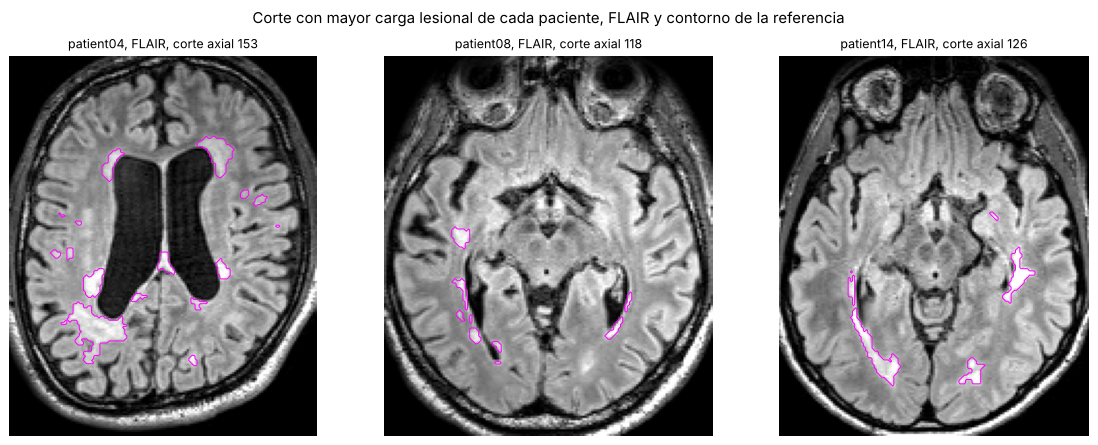

,Edad,Sexo,Tipo,EDSS,Volumen lesional (mL),N° lesiones,Lesiones < 50 vóxeles
Paciente,,,,,,,
patient04,25,M,SP,6.500,40.406,110,61
patient08,41,M,RR,5.000,6.326,50,32
patient14,42,M,RR,4.000,13.469,60,39


In [4]:
def corte_max(mascara, eje=2):
    """Corte con mayor área de la máscara a lo largo del eje dado."""
    ejes = tuple(i for i in range(3) if i != eje)
    return int(np.argmax(mascara.sum(axis=ejes)))


def tomar(vol, k, eje=2):
    """Corte 2D orientado para mostrar (anterior arriba)."""
    return np.rot90(np.take(vol, k, axis=eje))


def mostrar(ax, img, titulo='', vmin=None, vmax=None):
    if vmin is None:
        vmin, vmax = np.percentile(img, [1, 99.5])
    ax.imshow(img, cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(titulo); ax.axis('off')


fig, axs = plt.subplots(1, 3, figsize=(13, 5))
for ax, c in zip(axs, casos_em):
    k = corte_max(c['ref'])
    fl = c['img']['FLAIR']
    mostrar(ax, tomar(fl, k), f"{c['nombre']}, FLAIR, corte axial {k + c['bb'][2].start}",
            *np.percentile(fl[c['mask']], [0.5, 99.8]))
    ax.contour(tomar(c['ref'], k), [0.5], colors='magenta', linewidths=0.8)
fig.suptitle('Corte con mayor carga lesional de cada paciente, FLAIR y contorno de la referencia')
plt.tight_layout(); plt.show()

clinica = {'patient04': (25, 'M', 'SP', 6.5), 'patient08': (41, 'M', 'RR', 5.0), 'patient14': (42, 'M', 'RR', 4.0)}
filas = []
for c in casos_em:
    edad, sexo, tipo, edss = clinica.get(c['nombre'], (None,) * 4)
    lab, n = ndi.label(c['ref'], ndi.generate_binary_structure(3, 3))
    tam = np.bincount(lab.ravel())[1:]
    filas.append({'Paciente': c['nombre'], 'Edad': edad, 'Sexo': sexo, 'Tipo': tipo, 'EDSS': edss,
                  'Volumen lesional (mL)': c['ref'].sum() / 1000, 'N° lesiones': n,
                  'Lesiones < 50 vóxeles': int((tam < 50).sum())})
tabla_em = pd.DataFrame(filas).set_index('Paciente')
tabla_em

Los volúmenes (40,4, 6,3 y 13,5 mL) coinciden con los del enunciado, así que los datos son los mismos. Las tres cargas lesionales son muy distintas, y la mayoría de las lesiones mide menos de 50 vóxeles (50 mm³). Por eso, además del Dice, hacen falta métricas por lesión: un Dice global queda dominado por las pocas lesiones grandes.

### 1.4 Glioblastoma

Para cada paciente muestro las secuencias disponibles en el corte axial con mayor área tumoral, y la referencia sobre CT1 (amarillo necrosis (1), cian edema (2), magenta realce (3)).

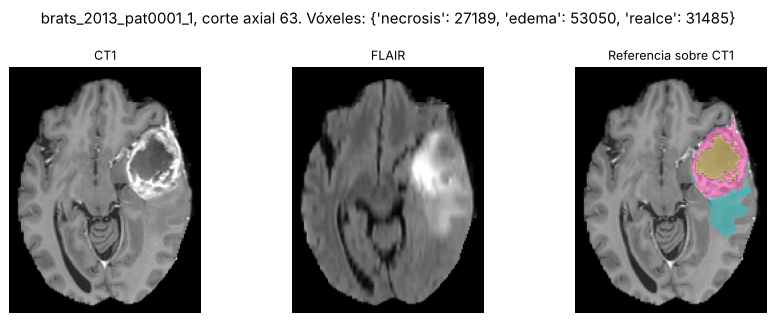

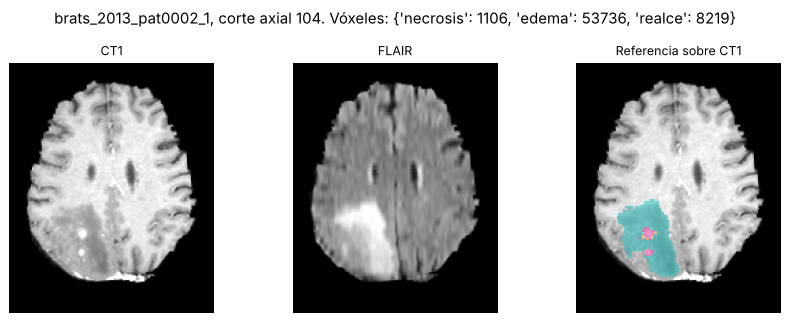

Nota: casos sustitutos de BraTS 2015; sólo traen FLAIR y CT1 (sin T1 ni T2).


In [5]:
COLORES_SEG = ListedColormap(['none', '#f2d16b', '#2ec4c4', '#e0389b'])

for c in casos_gbm:
    k = corte_max(c['ref_wt'])
    secs = [s for s in ['T1', 'CT1', 'T2', 'FLAIR'] if s in c['img']]
    fig, axs = plt.subplots(1, len(secs) + 1, figsize=(3.2 * (len(secs) + 1), 3.6))
    for ax, s in zip(axs, secs):
        mostrar(ax, tomar(c['img'][s], k), s)
    mostrar(axs[-1], tomar(c['img']['CT1'], k), 'Referencia sobre CT1')
    seg = tomar(c['seg'], k).astype(float)
    axs[-1].imshow(np.ma.masked_where(seg == 0, seg), cmap=COLORES_SEG, vmin=0, vmax=3, alpha=0.55,
                   interpolation='nearest')
    vols = {e: int((c['seg'] == i).sum()) for i, e in [(1, 'necrosis'), (2, 'edema'), (3, 'realce')]}
    fig.suptitle(f"{c['nombre']}, corte axial {k + c['bb'][2].start}. Vóxeles: {vols}")
    plt.tight_layout(); plt.show()

if GBM_ES_SUSTITUTO:
    print('Nota: casos sustitutos de BraTS 2015; sólo traen FLAIR y CT1 (sin T1 ni T2).')

En los dos tumores se ve lo que describe el enunciado: un anillo que realza en CT1 alrededor de un núcleo necrótico oscuro, y un edema extenso que sólo se ve bien en FLAIR. Por eso, en todos los *pipelines*, **el tumor completo se segmenta principalmente con FLAIR y el tumor realzante con CT1**.

> Ojo al interpretar los resultados: en LUMIERE la referencia es la segmentación automática de DeepBraTumIA validada por los autores, no un trazado manual. En los casos sustitutos de BraTS la referencia sí es manual.

## 2. Funciones comunes

Aquí van las funciones que usan los tres *pipelines*: normalización, postproceso morfológico, métricas, visualización y el experimento de parámetros. Así el mismo código evalúa todos los *pipelines*.

### 2.1 Normalización de intensidades

1. **Idea.** La RM no tiene unidades absolutas: el mismo tejido puede valer 100 en un paciente y 800 en otro. Para que un umbral o un centroide signifique lo mismo en todos los pacientes, llevo las intensidades del encéfalo a una escala común.
2. **Modelo.** Uso un *z-score* robusto dentro de la máscara de encéfalo $\Omega$:
$$ z(\mathbf{x}) = \frac{I(\mathbf{x}) - \operatorname{med}_\Omega(I)}{1{,}4826\cdot\operatorname{MAD}_\Omega(I)}, \qquad \operatorname{MAD}_\Omega(I) = \operatorname{med}_\Omega\big|I - \operatorname{med}_\Omega(I)\big| $$
donde $I(\mathbf{x})$ es la intensidad del vóxel $\mathbf{x}$, $\operatorname{med}_\Omega$ la mediana sobre los vóxeles del encéfalo y el factor 1,4826 hace que la MAD estime la desviación estándar si los datos fueran gaussianos. Fuera de $\Omega$ pongo $z=0$.
3. **Parámetros.** No tiene parámetros libres. Elegí mediana y MAD en vez de media y desviación estándar porque las lesiones, el tumor y el LCR forman colas en el histograma que moverían la media y la desviación. Con estadísticos robustos, $z$ queda anclado al parénquima normal, y en EM un umbral como $z>2{,}5$ significa "2,5 desviaciones más brillante que el tejido típico".
4. **Límites.** Supone que la mayoría del encéfalo es tejido normal. En un tumor muy grande la mediana se desplaza y los umbrales en $z$ cambian de significado. Tampoco corrige la inhomogeneidad de campo (las imágenes ya vienen corregidas). Probé ecualización de histograma y CLAHE, pero deforman la escala de intensidades de forma no lineal y distinta en cada paciente, lo que perjudica a los métodos que comparan intensidades entre pacientes.

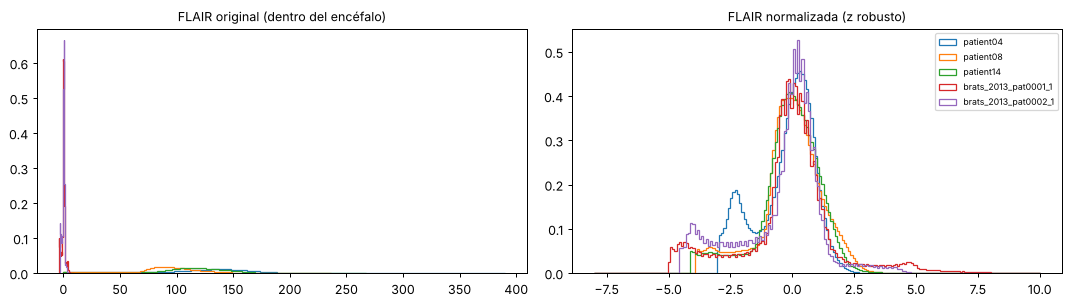

In [6]:
def normalizar(img, mascara):
    v = img[mascara]
    med = np.median(v)
    mad = 1.4826 * np.median(np.abs(v - med))
    z = (img - med) / mad
    z[~mascara] = 0
    return z.astype(np.float32)


for c in casos_em + casos_gbm:
    c['z'] = {s: normalizar(v, c['mask']) for s, v in c['img'].items()}

# Histogramas antes y después (FLAIR)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for c in casos_em + casos_gbm:
    axs[0].hist(c['img']['FLAIR'][c['mask']], 200, histtype='step', density=True, label=c['nombre'])
    axs[1].hist(c['z']['FLAIR'][c['mask']], 200, histtype='step', density=True, range=(-8, 10), label=c['nombre'])
axs[0].set_title('FLAIR original (dentro del encéfalo)'); axs[1].set_title('FLAIR normalizada (z robusto)')
axs[1].legend(fontsize=7); plt.tight_layout(); plt.show()

Después de normalizar, los picos de parénquima de todos los pacientes quedan centrados en 0 con un ancho parecido. El pico a la izquierda es el LCR (oscuro en FLAIR), y la cola derecha contiene la sustancia gris brillante, las lesiones y el tumor.

### 2.2 Postproceso morfológico

1. **Idea.** El clasificador decide vóxel a vóxel y deja errores que no respetan la forma de las estructuras: vóxeles sueltos, bordes rugosos y agujeros. El postproceso usa lo que sabemos de su forma, tamaño y posición.
2. **Modelo.** Con elemento estructurante $B$ (cruz 3D de 6 vecinos), la erosión es $S\ominus B=\{\mathbf{x}: B_\mathbf{x}\subseteq S\}$ y la dilatación $S\oplus B=\{\mathbf{x}: B_\mathbf{x}\cap S\neq\emptyset\}$. La apertura $S\circ B=(S\ominus B)\oplus B$ elimina estructuras más delgadas que $B$, y el cierre $(S\oplus B)\ominus B$ rellena huecos pequeños. Las componentes conexas se etiquetan con conectividad 26 y se filtran por tamaño. El llenado de agujeros agrega a $S$ el fondo que no está conectado con el borde del volumen.
   * **EM.** (i) *Criterio de posición*: elimino lo que cae a menos de 3 mm del borde del encéfalo ($S\cap(\Omega\ominus 3B)$), donde la corteza brillante y los artefactos del borde generan falsos positivos. (ii) *Criterio de tamaño*: elimino componentes de menos de 3 vóxeles. **No** aplico apertura: muchas lesiones miden pocos vóxeles y la apertura las borraría.
   * **GBM, tumor completo.** Apertura (2 iteraciones), me quedo con la **componente conexa más grande** (hay un solo tumor) y lleno agujeros (la necrosis queda dentro del tumor completo).
   * **GBM, tumor realzante.** Apertura (1 iteración), recorte al tumor completo y eliminación de componentes de menos de 50 vóxeles.
3. **Parámetros.** Fijé el margen (3 mm), los tamaños mínimos (3 y 50 vóxeles) y las iteraciones a partir de la anatomía, no del Dice: 3 mm es aproximadamente el grosor de la corteza; 3 vóxeles (3 mm³) está por debajo de la lesión más pequeña de la referencia que es visible en el corte; y el realce verdadero es un anillo de varios mm³. Su efecto se mide en la ablación (sección 6.4).
4. **Límites.** El margen de 3 mm elimina las lesiones yuxtacorticales, que existen en EM y cuentan como falsos negativos. La componente más grande falla en tumores multifocales: se perdería el segundo foco. Una apertura demasiado agresiva rompe el anillo realzante cuando es delgado.

In [7]:
CONN26 = ndi.generate_binary_structure(3, 3)    # conectividad 26 para componentes conexas
CRUZ = ndi.generate_binary_structure(3, 1)      # elemento estructurante de 6 vecinos


def quitar_pequenas(s, min_vox):
    lab, n = ndi.label(s, CONN26)
    if n == 0:
        return s
    tam = np.bincount(lab.ravel())[1:]
    return np.isin(lab, np.flatnonzero(tam >= min_vox) + 1)


def mayor_componente(s):
    lab, n = ndi.label(s, CONN26)
    if n == 0:
        return s
    tam = np.bincount(lab.ravel())[1:]
    return lab == (np.argmax(tam) + 1)


MARGEN_BORDE_EM = 3
MIN_VOX_EM = 3

def posproceso_em(s, caso):
    roi = caso.get('_roi')
    if roi is None:
        roi = caso['_roi'] = ndi.binary_erosion(caso['mask'], CRUZ, iterations=MARGEN_BORDE_EM)
    return quitar_pequenas(s & roi, MIN_VOX_EM)


def posproceso_wt(w):
    w = ndi.binary_opening(w, CRUZ, iterations=2)
    w = mayor_componente(w)
    return ndi.binary_fill_holes(w)


def posproceso_et(e, w):
    e = ndi.binary_opening(e & w, CRUZ, iterations=1)
    return quitar_pequenas(e, 50)

### 2.3 Métricas

1. **Idea.** Comparo la segmentación $S$ con la referencia $R$ (ambas como conjuntos de vóxeles dentro de la máscara de encéfalo) con medidas de solapamiento, de error de volumen y, en EM, de detección lesión por lesión.
2. **Modelo.** Métricas por vóxel:
$$ \text{Dice}=\frac{2|S\cap R|}{|S|+|R|},\quad \text{Jaccard}=\frac{|S\cap R|}{|S\cup R|},\quad \text{Sens}=\frac{|S\cap R|}{|R|},\quad \text{VPP}=\frac{|S\cap R|}{|S|},\quad \text{EV}=\frac{|S|-|R|}{|R|}$$
   Métricas por lesión (EM): etiqueto las componentes conexas (conectividad 26) de $R$, $\{R_i\}$, y de $S$, $\{S_j\}$.
   * **Tasa de detección** $=\#\{i: R_i\cap S\neq\emptyset\}/\#\{R_i\}$.
   * **Falsos positivos (FP lesionales)** $=\#\{j: S_j\cap R=\emptyset\}$.
   * **Dice de lesiones pequeñas**: $R^{p}=\bigcup\{R_i: |R_i|<50\}$ y $S^{p}=\bigcup\{S_j: S_j\cap R^{p}\neq\emptyset\ \text{o}\ (|S_j|<50 \text{ y } S_j\cap R=\emptyset)\}$, es decir, las componentes de $S$ que tocan una lesión pequeña más los falsos positivos pequeños. Después calculo $\text{Dice}(S^{p},R^{p})$.
3. **Parámetros.** El límite de 50 vóxeles y la conectividad 26 los fija el enunciado. Si $|S|=0$, defino VPP $=0$. En GBM reporto todo por separado para el tumor completo (WT) y el realzante (ET).
4. **Límites.** El Dice castiga más los errores en estructuras pequeñas y está dominado por las lesiones grandes. Detección y FP no miden el contorno, y una sola componente de $S$ que toca varias lesiones las "detecta" todas. La definición de $S^p$ es una elección mía, porque el enunciado no dice cómo recortar $S$. Además, la referencia no es la verdad: en GBM es automática (LUMIERE) y en EM es un consenso con variabilidad entre evaluadores, así que hay un techo de Dice que ningún método puede superar.

In [8]:
def metricas_voxel(S, R, mascara):
    S = S & mascara; R = R & mascara
    inter = (S & R).sum(); nS = S.sum(); nR = R.sum()
    return {'Dice': 2 * inter / (nS + nR) if nS + nR else 1.0,
            'Jaccard': inter / (S | R).sum() if (S | R).sum() else 1.0,
            'Sens': inter / nR if nR else np.nan,
            'VPP': inter / nS if nS else 0.0,
            'EV': (nS - nR) / nR if nR else np.nan}


def metricas_lesion(S, R, mascara, limite=50):
    S = S & mascara; R = R & mascara
    labR, nR = ndi.label(R, CONN26)
    labS, nS = ndi.label(S, CONN26)
    detectadas = np.setdiff1d(np.unique(labR[S]), [0])
    tocan_R = np.setdiff1d(np.unique(labS[R]), [0])
    tamR = np.bincount(labR.ravel(), minlength=nR + 1)
    tamS = np.bincount(labS.ravel(), minlength=nS + 1)
    Rp = np.isin(labR, np.flatnonzero(tamR[1:] < limite) + 1)
    tocan_Rp = np.setdiff1d(np.unique(labS[Rp]), [0])
    fp_pequenos = np.setdiff1d(np.flatnonzero(tamS[1:] < limite) + 1, tocan_R)
    Sp = np.isin(labS, np.union1d(tocan_Rp, fp_pequenos))
    den = Sp.sum() + Rp.sum()
    return {'Detección': len(detectadas) / nR if nR else np.nan,
            'FP lesiones': int(nS - len(tocan_R)),
            'Dice <50': 2 * (Sp & Rp).sum() / den if den else np.nan}


def evaluar(caso, seg):
    """Evaluación única para todos los pipelines. seg: máscara (EM) o tupla (WT, ET) (GBM)."""
    m = caso['mask']
    if caso['problema'] == 'EM':
        return {**metricas_voxel(seg, caso['ref'], m), **metricas_lesion(seg, caso['ref'], m)}
    wt, et = seg
    out = {f'{k} WT': v for k, v in metricas_voxel(wt, caso['ref_wt'], m).items()}
    out.update({f'{k} ET': v for k, v in metricas_voxel(et, caso['ref_et'], m).items()})
    return out


def puntaje(caso, seg):
    """Dice que se maximiza al elegir parámetros (en GBM, el promedio WT/ET)."""
    m = caso['mask']
    if caso['problema'] == 'EM':
        return metricas_voxel(seg, caso['ref'], m)['Dice']
    return 0.5 * (metricas_voxel(seg[0], caso['ref_wt'], m)['Dice'] +
                  metricas_voxel(seg[1], caso['ref_et'], m)['Dice'])


# Verificación rápida de las métricas con un caso hecho a mano
R = np.zeros((20, 20, 20), bool); R[2:6, 2:6, 2:6] = True; R[12:14, 12:14, 12:14] = True   # 64 + 8 vóx
S = np.zeros_like(R); S[2:6, 2:6, 2:4] = True; S[17:19, 2:4, 2:4] = True                   # 32 + 8 vóx
print(metricas_voxel(S, R, np.ones_like(R)))      # Dice = 2*32/(40+72) = 0.571
print(metricas_lesion(S, R, np.ones_like(R)))     # detecta 1 de 2, 1 FP

{'Dice': np.float64(0.5714285714285714), 'Jaccard': np.float64(0.4), 'Sens': np.float64(0.4444444444444444), 'VPP': np.float64(0.8), 'EV': np.float64(-0.4444444444444444)}
{'Detección': 0.5, 'FP lesiones': 1, 'Dice <50': np.float64(0.0)}


### 2.4 Visualización y experimento de parámetros

`figura_contornos` superpone, en el mismo corte, el contorno de la referencia y el de cada *pipeline*. `mapa_errores` pinta **verde** los verdaderos positivos, **rojo** los falsos positivos y **azul** los falsos negativos.

El **experimento de parámetros** sigue el enunciado. Cada *pipeline* tiene dos parámetros $(p_1,p_2)$ con una grilla de valores.

1. En el paciente 1 (patient04 en EM) segmento con toda la grilla, grafico el Dice y elijo los valores de mayor Dice.
2. Aplico esos valores, sin cambiarlos, a los pacientes 2 y 3.
3. Repito la búsqueda en los pacientes 2 y 3 con su propia referencia (el mejor Dice alcanzable).
4. La diferencia entre el paso 3 y el paso 2 es lo que se pierde al usar parámetros elegidos en otro paciente.

En GBM sólo hago el paso 1 en el primer paciente. Aplico esos mismos valores al segundo y, como información adicional, también calculo su óptimo.

In [9]:
def figura_contornos(caso, segs, titulo, eje=2, fondo='FLAIR', ref_key='ref', k=None):
    ref = caso[ref_key]
    k = corte_max(ref, eje) if k is None else k
    colores = ['#ff7f0e', '#2ca02c', '#1f77b4', '#d62728', '#9467bd']
    fig, axs = plt.subplots(1, len(segs) + 1, figsize=(3.6 * (len(segs) + 1), 4))
    img = caso['img'][fondo]
    vmin, vmax = np.percentile(img[caso['mask']], [0.5, 99.8])
    mostrar(axs[0], tomar(img, k, eje), f'{fondo} + referencia', vmin, vmax)
    axs[0].contour(tomar(ref, k, eje), [0.5], colors='magenta', linewidths=0.9)
    for ax, (nombre, s), col in zip(axs[1:], segs.items(), colores):
        mostrar(ax, tomar(img, k, eje), nombre, vmin, vmax)
        ax.contour(tomar(ref, k, eje), [0.5], colors='magenta', linewidths=0.9)
        if tomar(s, k, eje).any():
            ax.contour(tomar(s, k, eje), [0.5], colors=col, linewidths=0.9)
    fig.suptitle(f"{titulo} — {caso['nombre']}, corte {k + caso['bb'][eje].start} (magenta: referencia)")
    plt.tight_layout(); plt.show()


def mapa_errores(caso, segs, titulo, eje=2, fondo='FLAIR', ref_key='ref', k=None):
    ref = caso[ref_key]
    k = corte_max(ref, eje) if k is None else k
    fig, axs = plt.subplots(1, len(segs), figsize=(3.6 * len(segs), 4))
    axs = np.atleast_1d(axs)
    img = caso['img'][fondo]
    vmin, vmax = np.percentile(img[caso['mask']], [0.5, 99.8])
    for ax, (nombre, s) in zip(axs, segs.items()):
        S, R = tomar(s, k, eje), tomar(ref, k, eje)
        rgba = np.zeros(S.shape + (4,))
        rgba[S & R] = [0.1, 0.8, 0.1, 0.6]      # VP verde
        rgba[S & ~R] = [1.0, 0.1, 0.1, 0.85]    # FP rojo
        rgba[~S & R] = [0.1, 0.4, 1.0, 0.85]    # FN azul
        mostrar(ax, tomar(img, k, eje), nombre, vmin, vmax)
        ax.imshow(rgba, interpolation='nearest')
    fig.suptitle(f"{titulo} — {caso['nombre']}, corte {k + caso['bb'][eje].start}: verde VP, rojo FP, azul FN")
    plt.tight_layout(); plt.show()


def barrer(caso, pipeline, grilla1, grilla2):
    """Segmenta con toda la grilla (p1, p2) y devuelve una tabla de Dice."""
    cache = {}
    filas = []
    for p1 in grilla1:
        for p2 in grilla2:
            seg = pipeline(caso, p1, p2, cache=cache)
            filas.append({'p1': p1, 'p2': p2, 'Dice': puntaje(caso, seg)})
    return pd.DataFrame(filas)


def mejor(tabla):
    f = tabla.loc[tabla['Dice'].idxmax()]
    return f['p1'], f['p2'], f['Dice']


def graficar_barrido(tablas, nombres_p, titulo):
    fig, axs = plt.subplots(1, len(tablas), figsize=(4.3 * len(tablas), 3.4), squeeze=False)
    for ax, (paciente, t) in zip(axs[0], tablas.items()):
        for p2, g in t.groupby('p2'):
            ax.plot(g['p1'], g['Dice'], 'o-', ms=3, label=f'{nombres_p[1]}={p2:g}')
        p1, p2, d = mejor(t)
        ax.plot([p1], [d], 'k*', ms=12)
        ax.set_xlabel(nombres_p[0]); ax.set_ylabel('Dice'); ax.set_title(f'{paciente}: máx {d:.3f}')
        ax.grid(alpha=0.3)
    axs[0][-1].legend(fontsize=7, loc='best')
    fig.suptitle(titulo); plt.tight_layout(); plt.show()


def experimento_parametros(casos, pipeline, grilla1, grilla2, nombres_p, titulo):
    """Pasos 1 a 4 del enunciado. El primer caso de la lista es el paciente 1."""
    t0 = time.time()
    tablas = {c['nombre']: barrer(c, pipeline, grilla1, grilla2) for c in casos}
    graficar_barrido(tablas, nombres_p, f'{titulo}: Dice vs parámetros (★ = máximo)')
    p1, p2, _ = mejor(tablas[casos[0]['nombre']])
    filas = []
    for c in casos:
        t = tablas[c['nombre']]
        d_transf = t[(t.p1 == p1) & (t.p2 == p2)]['Dice'].iloc[0]
        q1, q2, d_prop = mejor(t)
        filas.append({'Paciente': c['nombre'],
                      f'{nombres_p[0]} (pac. 1)': p1, f'{nombres_p[1]} (pac. 1)': p2,
                      'Dice paso 2 (transferido)': d_transf,
                      f'{nombres_p[0]} propio': q1, f'{nombres_p[1]} propio': q2,
                      'Dice paso 3 (propio)': d_prop,
                      'Pérdida (paso 3 - paso 2)': d_prop - d_transf})
    res = pd.DataFrame(filas).set_index('Paciente')
    print(f'Tiempo del experimento: {time.time() - t0:.0f} s')
    return (p1, p2), res, tablas


def memo(cache, clave, fn):
    """Guarda resultados intermedios (p. ej. la imagen filtrada) para no recalcularlos en el barrido."""
    if cache is None:
        return fn()
    if clave not in cache:
        cache[clave] = fn()
    return cache[clave]


def muestra(X, n=100_000):
    """Submuestra fija de vóxeles para ajustar k-means / GMM más rápido."""
    rng = np.random.default_rng(SEMILLA)
    return X if len(X) <= n else X[rng.choice(len(X), n, replace=False)]


RESULTADOS_FINALES = {}   # (problema, pipeline, paciente) -> métricas
PARAMETROS = {}           # (problema, pipeline) -> (p1, p2)

## 3. *Pipeline* A — determinista: Perona-Malik + Otsu / umbral adaptativo

**Preprocesamiento:** normalización (2.1) y difusión anisotrópica de Perona y Malik. **Segmentación:** umbrales calculados sobre el histograma (Otsu y umbral adaptativo). **Postproceso:** 2.2.

### 3.1 Filtro: difusión anisotrópica de Perona y Malik

1. **Idea.** Suavizar el ruido **dentro** de las regiones homogéneas sin borrar los **bordes**. Un filtro gaussiano difunde la intensidad igual en todas direcciones y difumina el borde de una lesión pequeña contra el tejido. Perona y Malik hacen que la difusión se frene donde el gradiente es grande.
2. **Modelo.** La imagen $u(\mathbf{x},t)$ evoluciona según
$$ \frac{\partial u}{\partial t} = \nabla\cdot\big(g(\|\nabla u\|)\,\nabla u\big), \qquad g(s)=\exp\!\big(-(s/\kappa)^2\big), \qquad u(\mathbf{x},0)=z(\mathbf{x}). $$
   $g$ es el coeficiente de conducción: vale ≈1 cuando el gradiente es mucho menor que $\kappa$ (se difunde) y ≈0 cuando es mucho mayor (se preserva el borde). Discretizo en 3D con diferencias finitas hacia los 6 vecinos:
$$ u^{n+1}_\mathbf{x} = u^{n}_\mathbf{x} + \Delta t \sum_{d\in\{\pm x,\pm y,\pm z\}} g\big(|\nabla_d u^n_\mathbf{x}|\big)\,\nabla_d u^n_\mathbf{x}, \qquad \nabla_d u_\mathbf{x}=u_{\mathbf{x}+d}-u_\mathbf{x}.$$
   Con 6 vecinos el esquema explícito es estable para $\Delta t\le 1/6$, y uso $\Delta t=1/7$. En el borde del volumen el flujo es cero (condición de Neumann), así que la suma de intensidades se conserva.
3. **Parámetros.** $\kappa$ (en unidades de $z$) define qué salto de intensidad se considera "borde": con $\kappa$ pequeño casi no se difunde, y con $\kappa$ grande se difunde a través de los bordes como un gaussiano. $n$ es el número de iteraciones (el "tiempo" de difusión, $t=n\Delta t$). En EM, $\kappa$ es uno de los dos parámetros del experimento ($n=10$ fijo). En GBM los dos parámetros son $\kappa$ y $n$.
4. **Límites.** Si una lesión es más pequeña que el ruido o tiene poco contraste ($\|\nabla u\|<\kappa$), la difusión la borra igual que un gaussiano. El ruido muy intenso (gradientes $>\kappa$) se preserva como si fuera borde. Además, $\kappa$ depende de la escala de la imagen, y por eso conviene aplicarlo después de normalizar.

La implementación es sólo con `numpy` (sin librerías de filtrado).

In [10]:
def perona_malik(img, n_iter=10, kappa=1.0, dt=1/7):
    """Difusión anisotrópica de Perona-Malik en N dimensiones, g(s) = exp(-(s/kappa)^2)."""
    u = img.astype(np.float32).copy()
    for _ in range(n_iter):
        flujo = np.zeros_like(u)
        for eje in range(u.ndim):
            d = np.diff(u, axis=eje)                    # u[x+1] - u[x] a lo largo del eje
            f = np.exp(-(d / kappa) ** 2) * d           # g(|grad|) * grad
            antes = [(0, 0)] * u.ndim; antes[eje] = (1, 0)
            despues = [(0, 0)] * u.ndim; despues[eje] = (0, 1)
            # flujo que entra desde x+1 menos flujo que sale hacia x-1 (cero en el borde: Neumann)
            flujo += np.pad(f, despues) - np.pad(f, antes)
        u += dt * flujo
    return u

**Verificación.** Compruebo tres cosas en un fantoma sintético: un cubo brillante con ruido gaussiano.

1. Se conserva la suma de intensidades (Neumann).
2. Con $\kappa\to\infty$, $g\equiv1$ y el filtro es la ecuación del calor discreta. Tras $n$ pasos debe parecerse a un gaussiano de $\sigma=\sqrt{2n\Delta t}$.
3. Con $\kappa$ moderado, el borde del cubo queda más nítido que con el gaussiano de la misma "duración", y el ruido de las regiones planas baja igual.

1) Suma antes 15839.31, después 15839.31 (diferencia relativa 6.2e-08)
2) kappa -> inf vs gaussiano sigma=2.39: error medio absoluto 0.001 (ruido original 1.0)
3) Desv. estándar del ruido en el fondo: original 1.00, Perona-Malik 0.05, gaussiano 0.10
   Salto máximo en el borde: ideal 4.00, Perona-Malik 3.73, gaussiano 0.68


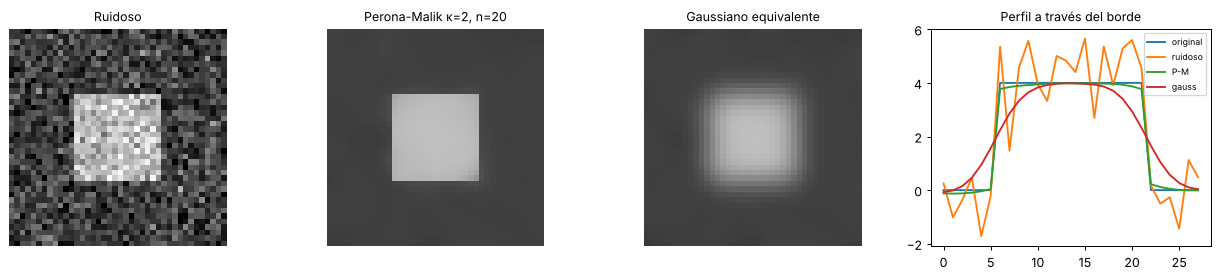

In [11]:
rng = np.random.default_rng(1)
fantoma = np.zeros((40, 40, 40), np.float32); fantoma[12:28, 12:28, 12:28] = 4.0
ruidoso = fantoma + rng.normal(0, 1, fantoma.shape).astype(np.float32)

n_v = 20
pm = perona_malik(ruidoso, n_iter=n_v, kappa=2.0)
calor = perona_malik(ruidoso, n_iter=n_v, kappa=1e6)               # g = 1
gauss = ndi.gaussian_filter(ruidoso, np.sqrt(2 * n_v / 7), mode='nearest')

print(f'1) Suma antes {ruidoso.sum():.2f}, después {pm.sum():.2f} (diferencia relativa {abs(pm.sum() - ruidoso.sum()) / abs(ruidoso.sum()):.1e})')
print(f'2) kappa -> inf vs gaussiano sigma={np.sqrt(2 * n_v / 7):.2f}: error medio absoluto {np.abs(calor - gauss)[5:-5, 5:-5, 5:-5].mean():.3f} (ruido original 1.0)')
plano = (slice(30, 38), slice(5, 35), slice(5, 35))
perfil = lambda v: v[20, 20, 6:34]
nitidez = lambda v: np.abs(np.diff(perfil(v))).max()
print(f'3) Desv. estándar del ruido en el fondo: original {ruidoso[plano].std():.2f}, Perona-Malik {pm[plano].std():.2f}, gaussiano {gauss[plano].std():.2f}')
print(f'   Salto máximo en el borde: ideal 4.00, Perona-Malik {nitidez(pm):.2f}, gaussiano {nitidez(gauss):.2f}')

fig, axs = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (t, v) in zip(axs[:3], [('Ruidoso', ruidoso), ('Perona-Malik κ=2, n=20', pm), ('Gaussiano equivalente', gauss)]):
    mostrar(ax, v[20], t, -2, 6)
for t, v in [('original', fantoma), ('ruidoso', ruidoso), ('P-M', pm), ('gauss', gauss)]:
    axs[3].plot(perfil(v), label=t)
axs[3].legend(fontsize=7); axs[3].set_title('Perfil a través del borde')
plt.tight_layout(); plt.show()

Las tres comprobaciones salen bien: la suma se conserva hasta el error de redondeo; con $\kappa$ muy grande el resultado coincide con un gaussiano (la pequeña diferencia es la discretización); y con $\kappa=2$ el ruido baja casi como con el gaussiano, pero el escalón del borde se mantiene mucho más alto.

### 3.2 Segmentación: Otsu y umbral adaptativo

1. **Idea.** Separar clases por intensidad con un umbral calculado a partir del histograma del propio paciente, no fijado a mano.
2. **Modelo.**
   * **Otsu**: dado el histograma normalizado $p_i$ con niveles $c_i$, se elige el umbral $t$ que maximiza la varianza entre clases
   $$ \sigma_B^2(t) = \omega_0(t)\,\omega_1(t)\,\big(\mu_0(t)-\mu_1(t)\big)^2, \qquad \omega_0=\sum_{c_i\le t}p_i,\ \ \mu_0=\frac{1}{\omega_0}\sum_{c_i\le t}c_i p_i ,$$
   y lo mismo para la clase 1. Es equivalente a minimizar la varianza dentro de cada clase.
   * **EM: Otsu + umbral adaptativo.** El primer Otsu sobre el encéfalo separa el LCR (oscuro en FLAIR) del parénquima $P$. Sobre $P$ calculo un umbral **adaptado a cada paciente** con estadísticos robustos: $$ S=\{\mathbf{x}\in P:\ u(\mathbf{x}) > \operatorname{med}_P(u) + c\cdot 1{,}4826\operatorname{MAD}_P(u)\}. $$ Una lesión es un *outlier* hiperintenso respecto del parénquima de ese paciente. No uso un segundo Otsu porque las lesiones son < 3 % del parénquima y Otsu supone clases de tamaño comparable: probándolo, el umbral cae entre sustancia blanca y sustancia gris, no entre tejido y lesión.
   * **GBM: Otsu jerárquico.** Aquí el tumor sí es una fracción grande. En FLAIR: $t_1=$ Otsu(encéfalo) separa el LCR, y $t_2=$ Otsu$(\{u>t_1\})$ separa el tejido hiperintenso (tumor + edema) del parénquima, lo que da el tumor completo $W$. En CT1: $t_3=$ Otsu$(\{\mathbf{x}\in W\})$ separa dentro del tumor el realce (brillante) de la necrosis y el edema, lo que da el tumor realzante $E$.
3. **Parámetros.** Otsu no tiene parámetros (uso 256 *bins*). En EM, $c$ es el segundo parámetro del experimento: con $c$ bajo aumentan la sensibilidad y los falsos positivos, y con $c$ alto pasa lo contrario.
4. **Límites.** Otsu falla cuando las clases son muy desbalanceadas o se solapan, como lesiones de EM contra sustancia gris. Un umbral global de intensidad no usa la posición: en FLAIR la corteza y el plexo coroideo son tan brillantes como algunas lesiones, y eso produce falsos positivos que sólo puede limpiar el postproceso.

In [12]:
def otsu(valores, nbins=256):
    h, bordes = np.histogram(valores, nbins)
    c = 0.5 * (bordes[:-1] + bordes[1:])
    p = h / h.sum()
    w0 = np.cumsum(p)
    m0 = np.cumsum(p * c)
    mt = m0[-1]
    sigma_b = (mt * w0 - m0) ** 2 / (w0 * (1 - w0) + 1e-12)
    return c[np.argmax(sigma_b[:-1])]


# Verificación: dos gaussianas con medias 0 y 4 y el mismo peso -> el umbral óptimo es 2
v = np.r_[np.random.default_rng(0).normal(0, 1, 50_000), np.random.default_rng(1).normal(4, 1, 50_000)]
print(f'Otsu en una mezcla 50/50 de N(0,1) y N(4,1): {otsu(v):.3f} (esperado ≈ 2)')

Otsu en una mezcla 50/50 de N(0,1) y N(4,1): 1.981 (esperado ≈ 2)


### 3.3 *Pipeline* A completo

Cada *pipeline* es una función con la firma `pipeline(caso, p1, p2, filtrar=True, posproceso=True, cache=None)`. Los dos *flags* sirven para la ablación (sección 6.4), y `cache` evita recalcular el filtrado al barrer el segundo parámetro.

In [13]:
N_ITER_PM_EM = 10

def em_A(caso, kappa, c, filtrar=True, posproceso=True, cache=None):
    m = caso['mask']
    z = caso['z']['FLAIR']
    # 1) preprocesamiento: normalización (ya hecha) + Perona-Malik
    u = memo(cache, ('pm', kappa), lambda: perona_malik(z, N_ITER_PM_EM, kappa)) if filtrar else z
    # 2) segmentación: Otsu separa LCR / parénquima, luego umbral adaptativo robusto en el parénquima
    t_lcr = otsu(u[m])
    P = m & (u > t_lcr)
    med = np.median(u[P]); mad = 1.4826 * np.median(np.abs(u[P] - med))
    S = P & (u > med + c * mad)
    # 3) postproceso
    return posproceso_em(S, caso) if posproceso else S


def gbm_A(caso, kappa, n_iter, filtrar=True, posproceso=True, cache=None):
    m = caso['mask']
    zf, zc = caso['z']['FLAIR'], caso['z']['CT1']
    if filtrar:
        F = memo(cache, ('pmF', kappa, n_iter), lambda: perona_malik(zf, int(n_iter), kappa))
        C = memo(cache, ('pmC', kappa, n_iter), lambda: perona_malik(zc, int(n_iter), kappa))
    else:
        F, C = zf, zc
    # tumor completo: Otsu jerárquico en FLAIR
    t1 = otsu(F[m]); t2 = otsu(F[m & (F > t1)])
    W = m & (F > t2)
    if posproceso:
        W = posproceso_wt(W)
    # tumor realzante: Otsu en CT1 dentro del tumor completo
    E = np.zeros_like(W)
    if W.any():
        E = W & (C > otsu(C[W]))
    if posproceso:
        E = posproceso_et(E, W)
    return W, E

### 3.4 Experimento de parámetros, *pipeline* A

**EM:** $p_1=\kappa\in\{0{,}25;0{,}5;1;2;4\}$ y $p_2=c\in\{1{,}5;2;2{,}5;3;3{,}5;4\}$. **GBM:** $p_1=\kappa\in\{0{,}25;0{,}5;1;2;4\}$ y $p_2=n\in\{2;5;10;20\}$. Elegí los rangos para cubrir desde "casi sin efecto" hasta "efecto exagerado" ($\kappa=4$ en unidades de $z$ ya cruza los bordes de las lesiones).

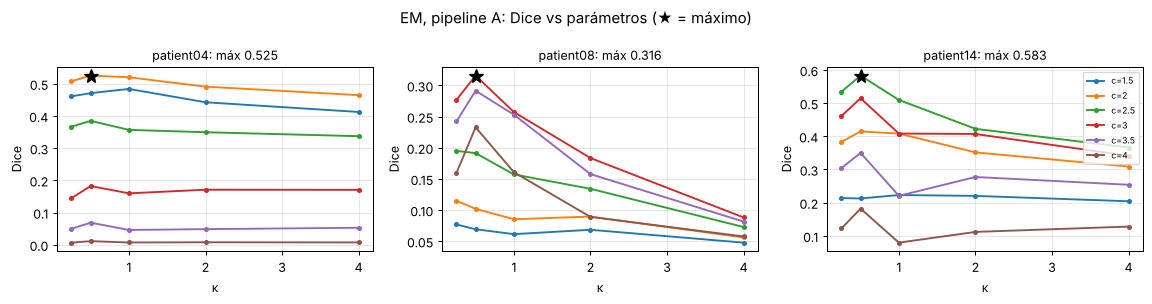

Tiempo del experimento: 24 s


,κ (pac. 1),c (pac. 1),Dice paso 2 (transferido),κ propio,c propio,Dice paso 3 (propio),Pérdida (paso 3 - paso 2)
Paciente,,,,,,,
patient04,0.500,2.000,0.525,0.500,2.000,0.525,0.000
patient08,0.500,2.000,0.102,0.500,3.000,0.316,0.214
patient14,0.500,2.000,0.415,0.500,2.500,0.583,0.168


In [14]:
GRILLA = {('EM', 'A'): ([0.25, 0.5, 1, 2, 4], [1.5, 2, 2.5, 3, 3.5, 4], ('κ', 'c')),
          ('GBM', 'A'): ([0.25, 0.5, 1, 2, 4], [2, 5, 10, 20], ('κ', 'n_iter'))}

g1, g2, nom = GRILLA[('EM', 'A')]
PARAMETROS[('EM', 'A')], exp_em_A, barr_em_A = experimento_parametros(casos_em, em_A, g1, g2, nom, 'EM, pipeline A')
exp_em_A

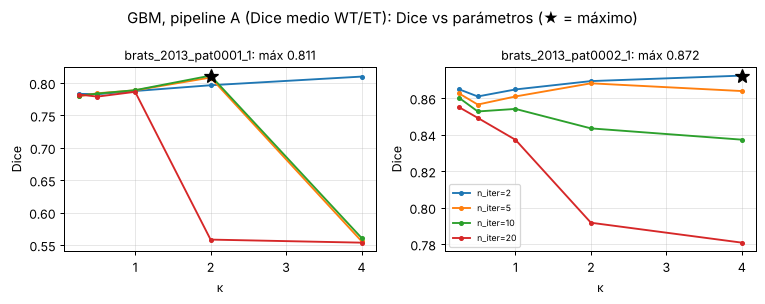

Tiempo del experimento: 90 s


,κ (pac. 1),n_iter (pac. 1),Dice paso 2 (transferido),κ propio,n_iter propio,Dice paso 3 (propio),Pérdida (paso 3 - paso 2)
Paciente,,,,,,,
brats_2013_pat0001_1,2.000,10.000,0.811,2.000,10.000,0.811,0.000
brats_2013_pat0002_1,2.000,10.000,0.843,4.000,2.000,0.872,0.029


In [15]:
g1, g2, nom = GRILLA[('GBM', 'A')]
PARAMETROS[('GBM', 'A')], exp_gbm_A, barr_gbm_A = experimento_parametros(casos_gbm, gbm_A, g1, g2, nom, 'GBM, pipeline A (Dice medio WT/ET)')
exp_gbm_A

### 3.5 Resultados del *pipeline* A (parámetros elegidos en el paciente 1)

In [16]:
def aplicar_y_registrar(problema, nombre_pipe, pipeline, casos):
    p1, p2 = PARAMETROS[(problema, nombre_pipe)]
    segs, filas = {}, []
    for c in casos:
        seg = pipeline(c, p1, p2)
        segs[c['nombre']] = seg
        met = evaluar(c, seg)
        RESULTADOS_FINALES[(problema, nombre_pipe, c['nombre'])] = met
        filas.append({'Paciente': c['nombre'], **met})
    print(f'{problema}, pipeline {nombre_pipe}: parámetros ({p1:g}, {p2:g}) elegidos en {casos[0]["nombre"]}')
    return segs, pd.DataFrame(filas).set_index('Paciente')

seg_em_A, tab = aplicar_y_registrar('EM', 'A', em_A, casos_em); display(tab)
seg_gbm_A, tab = aplicar_y_registrar('GBM', 'A', gbm_A, casos_gbm); display(tab)

EM, pipeline A: parámetros (0.5, 2) elegidos en patient04


,Dice,Jaccard,Sens,VPP,EV,Detección,FP lesiones,Dice <50
Paciente,,,,,,,,
patient04,0.525,0.356,0.425,0.687,-0.381,0.291,114,0.051
patient08,0.102,0.054,0.609,0.056,9.942,0.540,166,0.111
patient14,0.415,0.262,0.658,0.303,1.171,0.450,221,0.011


GBM, pipeline A: parámetros (2, 10) elegidos en brats_2013_pat0001_1


,Dice WT,Jaccard WT,Sens WT,VPP WT,EV WT,Dice ET,Jaccard ET,Sens ET,VPP ET,EV ET
Paciente,,,,,,,,,,
brats_2013_pat0001_1,0.875,0.778,0.867,0.884,-0.018,0.748,0.597,0.668,0.849,-0.214
brats_2013_pat0002_1,0.910,0.835,0.921,0.899,0.024,0.777,0.636,0.814,0.744,0.094


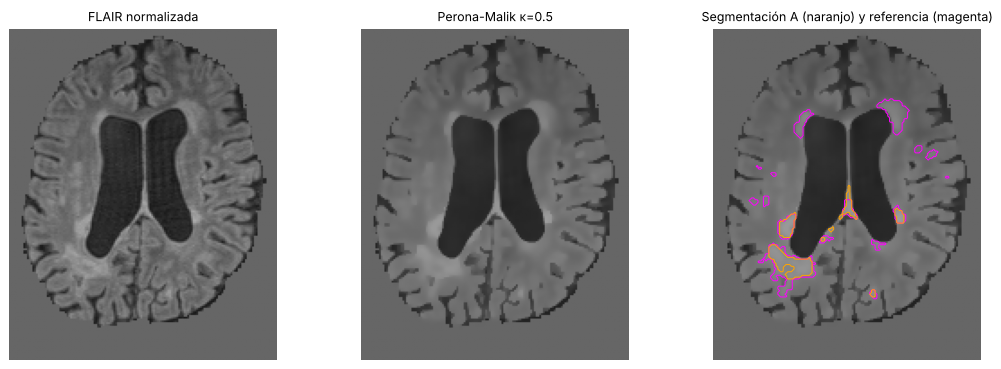

In [17]:
c = casos_em[0]
u = perona_malik(c['z']['FLAIR'], N_ITER_PM_EM, PARAMETROS[('EM', 'A')][0])
k = corte_max(c['ref'])
fig, axs = plt.subplots(1, 3, figsize=(12, 4.2))
mostrar(axs[0], tomar(c['z']['FLAIR'], k), 'FLAIR normalizada', -4, 6)
mostrar(axs[1], tomar(u, k), f"Perona-Malik κ={PARAMETROS[('EM', 'A')][0]:g}", -4, 6)
mostrar(axs[2], tomar(u, k), 'Segmentación A (naranjo) y referencia (magenta)', -4, 6)
axs[2].contour(tomar(c['ref'], k), [0.5], colors='magenta', linewidths=0.8)
axs[2].contour(tomar(seg_em_A[c['nombre']], k), [0.5], colors='orange', linewidths=0.8)
plt.tight_layout(); plt.show()

## 4. *Pipeline* B — espectral y agrupamiento: filtro de Butterworth en Fourier + *k-means*

**Preprocesamiento:** normalización y filtro pasa-bajos de Butterworth en el dominio de Fourier. **Segmentación:** *k-means*. **Postproceso:** 2.2.

### 4.1 Filtro: pasa-bajos de Butterworth en el dominio de Fourier

1. **Idea.** El ruido de la RM es aproximadamente blanco: reparte su energía en todas las frecuencias. La anatomía, en cambio, concentra su energía en las frecuencias bajas. Atenuar las frecuencias altas reduce el ruido, y hacerlo en el dominio de Fourier permite diseñar exactamente la respuesta en frecuencia.
2. **Modelo.** Con la transformada discreta 3D $F(\mathbf{k})=\mathcal{F}\{z\}(\mathbf{k})$ y la frecuencia radial normalizada $\rho(\mathbf{k})=\sqrt{k_x^2+k_y^2+k_z^2}$ (en ciclos/vóxel, $|k_i|\le 0{,}5$):
$$ H(\mathbf{k}) = \frac{1}{1+\big(\rho(\mathbf{k})/f_c\big)^{2n}}, \qquad z_f = \operatorname{Re}\,\mathcal{F}^{-1}\{H\cdot F\}.$$
   $f_c$ es la frecuencia de corte, donde $H=1/2$, y $n$ es el orden. A diferencia del filtro ideal (un escalón en $f_c$), la caída suave de Butterworth evita el *ringing* (fenómeno de Gibbs) alrededor de los bordes. $H(0)=1$ conserva la media.
3. **Parámetros.** $f_c$ es el primer parámetro del experimento: con $f_c$ bajo se suaviza mucho y se borran lesiones pequeñas; con $f_c\to0{,}87$ (la esquina del espectro) el filtro casi no actúa. El orden lo fijé en $n=2$, una caída moderada con muy poco *ringing*.
4. **Límites.** Es un filtro **lineal e isótropo**: suaviza los bordes igual que el ruido, a diferencia de Perona-Malik. Una lesión de 2–3 vóxeles tiene energía en frecuencias altas y se atenúa. La FFT supone que la imagen es periódica, así que los bordes del volumen se mezclan con el lado opuesto; aquí no importa porque el volumen está recortado con margen y fuera del encéfalo vale 0.

Implementado con `numpy.fft`. Muestro el espectro antes y después del filtro.

fc = 1e6 -> error máximo vs original: 2.384185791015625e-07


media antes -0.10856, después (fc=0.1) -0.10856


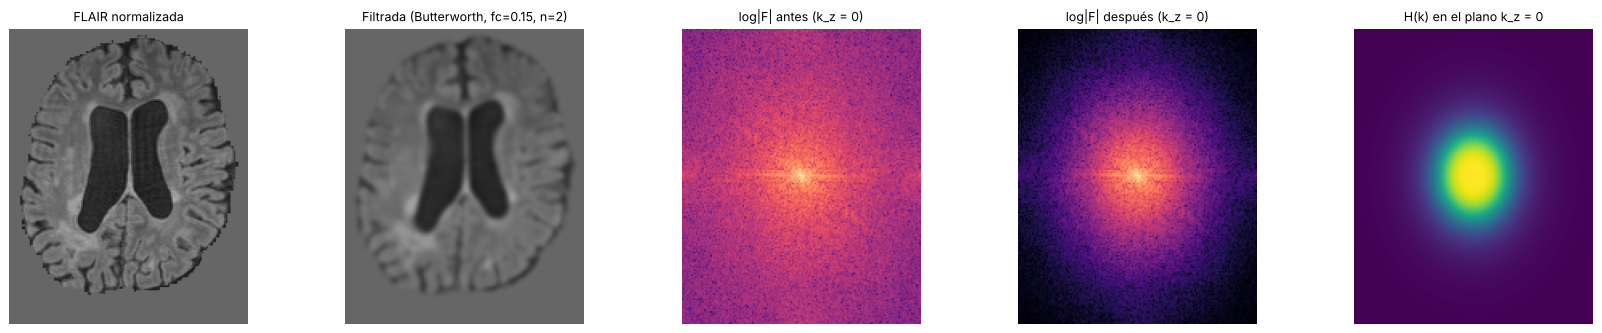

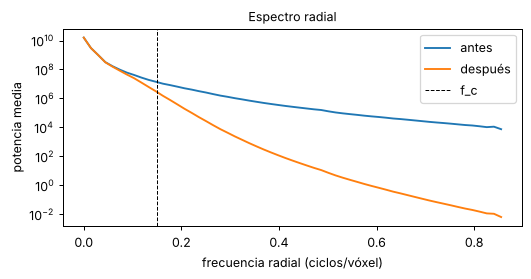

In [18]:
def radio_frecuencia(forma):
    k = np.meshgrid(*[np.fft.fftfreq(n) for n in forma], indexing='ij')
    return np.sqrt(sum(ki ** 2 for ki in k))


def butterworth_pb(img, fc=0.2, orden=2):
    """Filtro pasa-bajos de Butterworth 3D aplicado en el dominio de Fourier (numpy.fft)."""
    F = np.fft.fftn(img)
    H = 1.0 / (1.0 + (radio_frecuencia(img.shape) / fc) ** (2 * orden))
    return np.real(np.fft.ifftn(F * H)).astype(np.float32)


# Verificación 1: con fc enorme el filtro es la identidad; H(0) = 1 conserva la media
z = casos_em[0]['z']['FLAIR']
print('fc = 1e6 -> error máximo vs original:', float(np.abs(butterworth_pb(z, 1e6) - z).max()))
print(f'media antes {z.mean():.5f}, después (fc=0.1) {butterworth_pb(z, 0.1).mean():.5f}')

# Verificación 2: espectro antes y después en el corte axial central del espacio de frecuencias
fc_demo = 0.15
zf = butterworth_pb(z, fc_demo)
espectro = lambda v: np.log1p(np.abs(np.fft.fftshift(np.fft.fftn(v))))
Ea, Ed = espectro(z), espectro(zf)
kz = Ea.shape[2] // 2
H2d = 1 / (1 + (radio_frecuencia(z.shape)[:, :, 0] / fc_demo) ** 4)
k = corte_max(casos_em[0]['ref'])
fig, axs = plt.subplots(1, 5, figsize=(19, 3.8))
mostrar(axs[0], tomar(z, k), 'FLAIR normalizada', -4, 6)
mostrar(axs[1], tomar(zf, k), f'Filtrada (Butterworth, fc={fc_demo}, n=2)', -4, 6)
vmax = Ea[:, :, kz].max()
axs[2].imshow(np.rot90(Ea[:, :, kz]), cmap='magma', vmin=0, vmax=vmax); axs[2].set_title('log|F| antes (k_z = 0)')
axs[3].imshow(np.rot90(Ed[:, :, kz]), cmap='magma', vmin=0, vmax=vmax); axs[3].set_title('log|F| después (k_z = 0)')
axs[4].imshow(np.rot90(np.fft.fftshift(H2d)), cmap='viridis'); axs[4].set_title('H(k) en el plano k_z = 0')
for a in axs[2:]: a.axis('off')
plt.tight_layout(); plt.show()

# Perfil radial del espectro de potencia
rho = radio_frecuencia(z.shape).ravel()
bins = np.linspace(0, 0.87, 60)
idx = np.digitize(rho, bins)
pot = lambda v: np.bincount(idx, (np.abs(np.fft.fftn(v)) ** 2).ravel(), minlength=len(bins) + 1)[1:len(bins)] / np.maximum(np.bincount(idx, minlength=len(bins) + 1)[1:len(bins)], 1)
plt.figure(figsize=(6, 3.2))
plt.semilogy(bins[:-1], pot(z), label='antes'); plt.semilogy(bins[:-1], pot(zf), label='después')
plt.axvline(fc_demo, color='k', ls='--', lw=0.8, label='f_c')
plt.xlabel('frecuencia radial (ciclos/vóxel)'); plt.ylabel('potencia media'); plt.legend(); plt.title('Espectro radial')
plt.tight_layout(); plt.show()

Con $f_c$ enorme se recupera la imagen original (error de máquina) y la media no cambia. En el espectro se ve que, después del filtro, la energía por encima de $f_c$ cae varios órdenes de magnitud, mientras que el centro (la anatomía gruesa) queda igual. En la imagen, el ruido de grano fino desaparece, pero los bordes de las lesiones también se ablandan.

### 4.2 Segmentación: *k-means*

1. **Idea.** Agrupar los vóxeles en $k$ grupos por su vector de intensidades, sin usar la referencia. Las lesiones (EM) o el tumor y el realce (GBM) deberían quedar en los grupos más brillantes de FLAIR y CT1.
2. **Modelo.** Con $\mathbf{y}_\mathbf{x}\in\mathbb{R}^d$ el vector de intensidades filtradas del vóxel $\mathbf{x}$, *k-means* minimiza la inercia
$$ J=\sum_{j=1}^k\sum_{\mathbf{x}\in C_j}\|\mathbf{y}_\mathbf{x}-\boldsymbol{\mu}_j\|^2 $$
   alternando la asignación de cada vóxel al centroide más cercano y la actualización $\boldsymbol{\mu}_j$ = media del grupo (algoritmo de Lloyd, inicializado con *k-means++*). Uso `sklearn.cluster.KMeans` ajustado en una submuestra fija de 100 000 vóxeles del encéfalo y después asigno todos los vóxeles.
   * **EM** ($d=1$, FLAIR): la lesión es el grupo de centroide más brillante.
   * **GBM** ($d$ = todas las secuencias disponibles, $\mathbf{y}=(z_{FLAIR}, z_{CT1},\dots)$), en dos etapas: **(i)** *k-means* con $k$ grupos en el encéfalo, y el tumor completo es la unión de los grupos con centroide FLAIR $>1$ (más brillante que el parénquima típico; siempre incluyo el más brillante); **(ii)** dentro del tumor completo, *k-means* con 3 grupos (necrosis, edema, realce), y el realce es el grupo con mayor centroide en CT1.
3. **Parámetros.** $f_c$ y $k$ son los dos parámetros del experimento. Con $k$ pequeño, el grupo más brillante mezcla lesión y sustancia gris; con $k$ grande, las lesiones se reparten en varios grupos y el más brillante se queda sólo con su núcleo. En GBM, el umbral 1 sobre el centroide y los 3 grupos de la segunda etapa los fijé por la anatomía: necrosis, edema y realce son las tres clases de la referencia.
4. **Límites.** *k-means* supone grupos esféricos de tamaño parecido, y una lesión de EM que ocupa el 1 % del encéfalo casi nunca forma un grupo propio. Por eso el grupo más brillante suele mezclarse con la sustancia gris. Además, no usa información espacial: cada vóxel se clasifica solo. El resultado depende de la inicialización, que fijo con una semilla.

In [19]:
def em_B(caso, fc, k, filtrar=True, posproceso=True, cache=None):
    m = caso['mask']
    z = caso['z']['FLAIR']
    u = memo(cache, ('bw', fc), lambda: butterworth_pb(z, fc)) if filtrar else z
    X = u[m].reshape(-1, 1)
    km = KMeans(int(k), n_init=3, random_state=SEMILLA).fit(muestra(X))
    lab = km.predict(X)
    S = np.zeros_like(m)
    S[m] = lab == np.argmax(km.cluster_centers_[:, 0])
    return posproceso_em(S, caso) if posproceso else S


def secuencias_gbm(caso):
    """Orden de las columnas del vector de intensidades: FLAIR, CT1 y, si existen, T2 y T1."""
    return [s for s in ['FLAIR', 'CT1', 'T2', 'T1'] if s in caso['z']]


def gbm_B(caso, fc, k, filtrar=True, posproceso=True, cache=None):
    m = caso['mask']
    secs = secuencias_gbm(caso)
    if filtrar:
        vols = [memo(cache, ('bw', s, fc), lambda s=s: butterworth_pb(caso['z'][s], fc)) for s in secs]
    else:
        vols = [caso['z'][s] for s in secs]
    X = np.stack([v[m] for v in vols], axis=1)
    # etapa 1: tumor completo
    km = KMeans(int(k), n_init=3, random_state=SEMILLA).fit(muestra(X))
    cen = km.cluster_centers_
    grupos_tumor = np.union1d(np.flatnonzero(cen[:, 0] > 1.0), [np.argmax(cen[:, 0])])
    W = np.zeros_like(m); W[m] = np.isin(km.predict(X), grupos_tumor)
    if posproceso:
        W = posproceso_wt(W)
    # etapa 2: realce dentro del tumor completo
    E = np.zeros_like(W)
    if W.sum() > 10:
        Xw = np.stack([v[W] for v in vols], axis=1)
        km2 = KMeans(3, n_init=3, random_state=SEMILLA).fit(muestra(Xw))
        E[W] = km2.predict(Xw) == np.argmax(km2.cluster_centers_[:, 1])
    if posproceso:
        E = posproceso_et(E, W)
    return W, E

### 4.3 Experimento de parámetros, *pipeline* B

**EM y GBM:** $p_1=f_c\in\{0{,}05;0{,}1;0{,}15;0{,}2;0{,}3;0{,}5\}$ ciclos/vóxel y $p_2=k$. En EM uso $k\in\{3,\dots,7\}$ y en GBM $k\in\{3,4,5,6,8\}$.

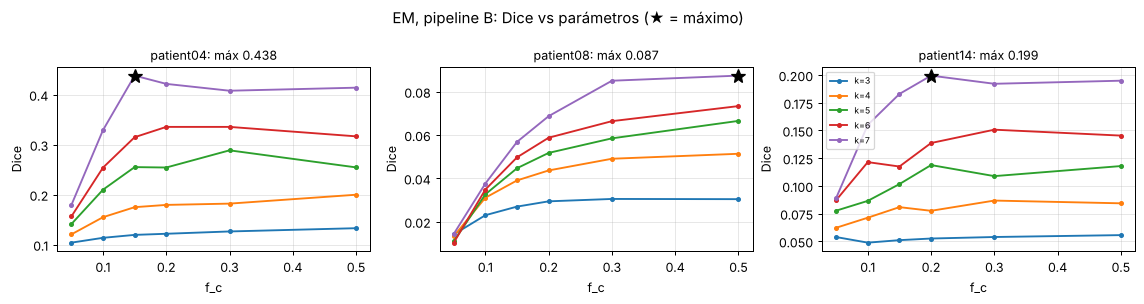

Tiempo del experimento: 39 s


,f_c (pac. 1),k (pac. 1),Dice paso 2 (transferido),f_c propio,k propio,Dice paso 3 (propio),Pérdida (paso 3 - paso 2)
Paciente,,,,,,,
patient04,0.150,7.000,0.438,0.150,7.000,0.438,0.000
patient08,0.150,7.000,0.057,0.500,7.000,0.087,0.031
patient14,0.150,7.000,0.183,0.200,7.000,0.199,0.017


In [20]:
GRILLA[('EM', 'B')] = ([0.05, 0.1, 0.15, 0.2, 0.3, 0.5], [3, 4, 5, 6, 7], ('f_c', 'k'))
GRILLA[('GBM', 'B')] = ([0.05, 0.1, 0.15, 0.2, 0.3, 0.5], [3, 4, 5, 6, 8], ('f_c', 'k'))

g1, g2, nom = GRILLA[('EM', 'B')]
PARAMETROS[('EM', 'B')], exp_em_B, barr_em_B = experimento_parametros(casos_em, em_B, g1, g2, nom, 'EM, pipeline B')
exp_em_B

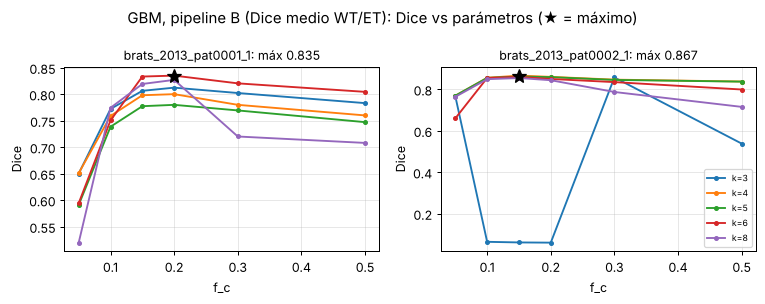

Tiempo del experimento: 72 s


,f_c (pac. 1),k (pac. 1),Dice paso 2 (transferido),f_c propio,k propio,Dice paso 3 (propio),Pérdida (paso 3 - paso 2)
Paciente,,,,,,,
brats_2013_pat0001_1,0.200,6.000,0.835,0.200,6.000,0.835,0.000
brats_2013_pat0002_1,0.200,6.000,0.850,0.150,4.000,0.867,0.016


In [21]:
g1, g2, nom = GRILLA[('GBM', 'B')]
PARAMETROS[('GBM', 'B')], exp_gbm_B, barr_gbm_B = experimento_parametros(casos_gbm, gbm_B, g1, g2, nom, 'GBM, pipeline B (Dice medio WT/ET)')
exp_gbm_B

### 4.4 Resultados del *pipeline* B (parámetros elegidos en el paciente 1)

In [22]:
seg_em_B, tab = aplicar_y_registrar('EM', 'B', em_B, casos_em); display(tab)
seg_gbm_B, tab = aplicar_y_registrar('GBM', 'B', gbm_B, casos_gbm); display(tab)

EM, pipeline B: parámetros (0.15, 7) elegidos en patient04


,Dice,Jaccard,Sens,VPP,EV,Detección,FP lesiones,Dice <50
Paciente,,,,,,,,
patient04,0.438,0.280,0.619,0.339,0.828,0.482,59,0.011
patient08,0.057,0.029,0.480,0.030,14.887,0.340,22,0.001
patient14,0.183,0.101,0.717,0.105,5.836,0.400,44,0.002


GBM, pipeline B: parámetros (0.2, 6) elegidos en brats_2013_pat0001_1


,Dice WT,Jaccard WT,Sens WT,VPP WT,EV WT,Dice ET,Jaccard ET,Sens ET,VPP ET,EV ET
Paciente,,,,,,,,,,
brats_2013_pat0001_1,0.885,0.793,0.820,0.961,-0.147,0.786,0.647,0.692,0.909,-0.239
brats_2013_pat0002_1,0.900,0.817,0.844,0.963,-0.123,0.801,0.668,0.680,0.974,-0.302


## 5. *Pipeline* C — probabilístico con contexto: mezcla gaussiana + ICM sobre un MRF

**Preprocesamiento:** normalización y suavizado gaussiano leve. **Segmentación:** modelo de mezcla gaussiana (algoritmo EM) para la verosimilitud de cada clase y un campo aleatorio de Markov (Potts) resuelto con ICM. **Postproceso:** 2.2.

### 5.1 Filtro: suavizado gaussiano leve

1. **Idea.** Reducir un poco el ruido antes de estimar las densidades, pero sin el efecto fuerte de B. El contexto espacial lo aporta el MRF y no el filtro.
2. **Modelo.** $z_s = G_\sigma * z$, con $G_\sigma(\mathbf{x})\propto e^{-\|\mathbf{x}\|^2/2\sigma^2}$ (`scipy.ndimage.gaussian_filter`).
3. **Parámetros.** Fijé $\sigma=0{,}7$ vóxeles, un núcleo de ~3 vóxeles de ancho que no borra lesiones de 3 mm. Los dos parámetros del experimento están en la segmentación.
4. **Límites.** Es lineal e isótropo, igual que Butterworth (de hecho es un pasa-bajos gaussiano). Con $\sigma$ grande borraría las lesiones pequeñas.

### 5.2 Segmentación: modelo de mezcla gaussiana (algoritmo EM)

1. **Idea.** Modelar el histograma (o la distribución multivariada) como una suma de gaussianas, una por tejido, y clasificar cada vóxel por la clase que mejor explica su intensidad.
2. **Modelo.** $p(\mathbf{y}) = \sum_{j=1}^K \pi_j\,\mathcal{N}(\mathbf{y};\boldsymbol\mu_j,\Sigma_j)$, con pesos $\pi_j$, medias $\boldsymbol\mu_j$ y covarianzas $\Sigma_j$. El algoritmo EM alterna el **paso E** (responsabilidades $\gamma_{\mathbf{x}j}\propto\pi_j\mathcal N(\mathbf y_\mathbf x;\boldsymbol\mu_j,\Sigma_j)$) y el **paso M** (re-estimar $\pi_j,\boldsymbol\mu_j,\Sigma_j$ como medias ponderadas por $\gamma$) hasta que converge la log-verosimilitud. Uso `sklearn.mixture.GaussianMixture` sobre una submuestra fija. La energía unaria de asignar la clase $j$ al vóxel $\mathbf{x}$ es $$U_j(\mathbf{x}) = -\log\big(\pi_j\,\mathcal{N}(\mathbf y_\mathbf x;\boldsymbol\mu_j,\Sigma_j)\big).$$
   * **EM (FLAIR).** Ajusto $K=3$ gaussianas al encéfalo (LCR, sustancia blanca y sustancia gris; el pico de la sustancia gris absorbe las lesiones, que son muy pocas). Agrego explícitamente una **cuarta clase "lesión"** como *outlier* hiperintenso de la clase más brillante: $\mathcal N(\mu_3 + c\,\sigma_3,\ (1{,}5\sigma_3)^2)$ con peso $\pi_L=0{,}03$ (y los otros pesos reescalados por $0{,}97$). Hice esto porque, al probar una GMM libre de 4 componentes, la cuarta componente se iba a la sustancia gris en patient08 y patient14, que tienen poca carga lesional.
   * **GBM.** GMM de $K$ componentes sobre el vector de secuencias, con la misma regla de dos etapas de B (tumor completo = componentes con media FLAIR $>1$; después, dentro del tumor completo, GMM de 3 componentes con realce = mayor media en CT1). En las dos etapas aplico ICM.
3. **Parámetros.** En EM: $c$ (desplazamiento de la clase lesión, en desviaciones de la clase más brillante) y $\beta$ del MRF. En GBM: $K$ y $\beta$. El ancho $1{,}5\sigma_3$ y el peso 0,03 los fijé por el orden de magnitud de la carga lesional (1–3 % del encéfalo).
4. **Límites.** EM converge a un máximo local que depende de la inicialización. Supone clases gaussianas, y el volumen parcial (vóxeles mitad tejido, mitad LCR) produce "clases" intermedias que no existen. Si una clase tiene muy pocos vóxeles, la GMM libre no la encuentra, y por eso en EM la clase lesión se define a mano.

### 5.3 Campo aleatorio de Markov (Potts) e ICM

1. **Idea.** Los tejidos son regiones conexas: si todos mis vecinos son sustancia blanca, lo más probable es que yo también lo sea. Un MRF agrega ese **contexto** como probabilidad *a priori* sobre el mapa de etiquetas, y así corrige vóxeles aislados que la intensidad sola clasificaría mal.
2. **Modelo.** El mapa de etiquetas $\mathbf{l}=\{l_\mathbf{x}\}$ es un MRF con potencial de Potts sobre la vecindad de 6 vecinos $\mathcal{N}(\mathbf{x})$. La segmentación MAP minimiza la energía
$$ E(\mathbf l) = \sum_\mathbf{x} U_{l_\mathbf{x}}(\mathbf{x}) \;+\; \beta\sum_{\langle\mathbf{x},\mathbf{x}'\rangle} \big[l_\mathbf{x}\neq l_{\mathbf{x}'}\big]. $$
   El primer término es la verosimilitud (5.2) y el segundo penaliza con $\beta$ a cada par de vecinos $\langle\mathbf x,\mathbf x'\rangle$ (contado una vez) con etiquetas distintas. **ICM** (*Iterated Conditional Modes*, Besag 1986) minimiza localmente: parte de la clasificación de máxima verosimilitud $l^{(0)}_\mathbf{x}=\arg\min_j U_j(\mathbf x)$ y repite la **regla de actualización**
$$ l^{(t+1)}_\mathbf{x} = \arg\min_{j}\Big[\,U_j(\mathbf x) + \beta\,\big(|\mathcal N(\mathbf x)| - n_j(\mathbf x)\big)\Big],\qquad n_j(\mathbf x)=\#\{\mathbf x'\in\mathcal N(\mathbf x): l^{(t)}_{\mathbf x'}=j\}$$
   hasta que cambia menos del 0,01 % de los vóxeles (máximo 10 iteraciones). Para vectorizarla sin perder las garantías de ICM secuencial, actualizo en **dos medias pasadas tipo tablero de ajedrez**: primero los vóxeles con $x+y+z$ par y después los impares. Como dos vóxeles del mismo color nunca son vecinos, cada media pasada equivale a visitarlos uno por uno, y la energía no puede subir. Cuento los vecinos de cada clase con desplazamientos de `numpy`, sin librerías.
3. **Parámetros.** $\beta$ pesa el contexto frente a la intensidad. Con $\beta=0$ se recupera la clasificación de máxima verosimilitud sin contexto, que es la ablación pedida. Con $\beta$ grande el mapa se vuelve demasiado liso y desaparecen las estructuras pequeñas. $\beta$ es uno de los dos parámetros del experimento.
4. **Límites.** ICM es voraz: converge a un mínimo **local** que depende de la inicialización (otros métodos, como *graph cuts* o *simulated annealing*, buscan el global). El prior de Potts favorece regiones grandes y compactas, lo que **va en contra de lesiones pequeñas y numerosas** como las de EM: una lesión de 3 vóxeles rodeada de sustancia blanca paga casi 6β por vóxel. Una primera versión que actualizaba todos los vóxeles a la vez (síncrona) oscilaba y la energía no bajaba de forma monótona; por eso uso el tablero de ajedrez y lo verifico abajo.

In [23]:
def contar_vecinos(lab, j):
    """n_j(x): número de los 6 vecinos de x con etiqueta j (fuera del volumen no cuenta)."""
    b = (lab == j).astype(np.float32)
    n = np.zeros_like(b)
    n[1:, :, :] += b[:-1, :, :]; n[:-1, :, :] += b[1:, :, :]
    n[:, 1:, :] += b[:, :-1, :]; n[:, :-1, :] += b[:, 1:, :]
    n[:, :, 1:] += b[:, :, :-1]; n[:, :, :-1] += b[:, :, 1:]
    return n


def energia_mrf(U, lab, mascara, beta):
    """E(l) = sum U_l(x) + beta * #pares de vecinos con etiqueta distinta (cada par una vez)."""
    unaria = np.take_along_axis(U, np.maximum(lab, 0)[None], 0)[0][mascara].sum()
    K = U.shape[0]
    iguales = sum(contar_vecinos(lab, j)[lab == j].sum() for j in range(K))
    vecinos = sum(contar_vecinos(lab, j) for j in range(K))[mascara].sum()   # vecinos etiquetados
    return float(unaria + beta * (vecinos - iguales) / 2)   # /2: cada par se contó desde sus dos vóxeles


def icm(U, mascara, beta, n_iter=10, tol=1e-4, registrar=False):
    """ICM sobre un MRF de Potts. U: (K, X, Y, Z) energías unarias. Fuera de la máscara la etiqueta es -1."""
    K = U.shape[0]
    lab = np.argmin(U, axis=0)
    lab[~mascara] = -1
    energias = [energia_mrf(U, lab, mascara, beta)] if registrar else []
    if beta == 0:
        return lab, energias
    ix, iy, iz = np.indices(lab.shape, sparse=True)
    color = (ix + iy + iz) % 2                    # tablero de ajedrez 3D
    for _ in range(n_iter):
        cambio = 0.0
        for c in (0, 1):
            n = np.stack([contar_vecinos(lab, j) for j in range(K)])
            total = n.sum(axis=0)
            E = U + beta * (total[None] - n)      # regla de actualización
            nuevo = np.argmin(E, axis=0)
            actualizar = mascara & (color == c)
            cambio += (nuevo != lab)[actualizar].sum() / mascara.sum()
            lab = np.where(actualizar, nuevo, lab)
        if registrar:
            energias.append(energia_mrf(U, lab, mascara, beta))
        if cambio < tol:
            break
    return lab, energias

**Verificación del MRF.** Uso un fantoma de dos clases (una esfera dentro de un cubo) con ruido fuerte, y la energía unaria de dos gaussianas conocidas. Compruebo que:

1. con $\beta=0$ el resultado es exactamente la clasificación de máxima verosimilitud;
2. la energía $E(\mathbf l)$ disminuye en cada iteración de ICM;
3. el error de clasificación baja al aumentar $\beta$ hasta cierto punto y sube si $\beta$ es excesivo.

1) beta=0 idéntico a máxima verosimilitud: True
2) energías por iteración: [81260. 40075. 34703. 34460. 34440. 34436.] -> monótona decreciente: True
3) error de clasificación vs beta: {0: '20.428%', 0.25: '7.516%', 0.5: '1.636%', 1: '0.547%', 2: '0.588%', 4: '0.622%', 8: '0.622%'}


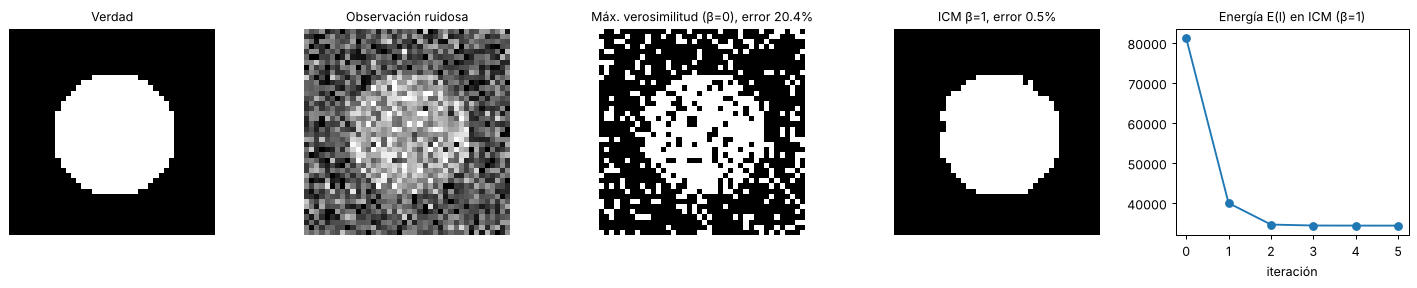

In [24]:
rng = np.random.default_rng(3)
xx, yy, zz = np.mgrid[:40, :40, :40]
verdad = ((xx - 20) ** 2 + (yy - 20) ** 2 + (zz - 20) ** 2) < 12 ** 2
obs = np.where(verdad, 1.0, 0.0) + rng.normal(0, 0.6, verdad.shape)
U_f = np.stack([0.5 * ((obs - mu) / 0.6) ** 2 for mu in (0.0, 1.0)]).astype(np.float32)
todo = np.ones_like(verdad)

ml = np.argmin(U_f, 0)
lab0, _ = icm(U_f, todo, beta=0)
print('1) beta=0 idéntico a máxima verosimilitud:', np.array_equal(lab0, ml))
lab1, E = icm(U_f, todo, beta=1.0, registrar=True)
print('2) energías por iteración:', np.round(E, 0), '-> monótona decreciente:', bool(np.all(np.diff(E) <= 0)))
errores = {b: ((icm(U_f, todo, b)[0] == 1) != verdad).mean() for b in [0, 0.25, 0.5, 1, 2, 4, 8]}
print('3) error de clasificación vs beta:', {k: f'{v:.3%}' for k, v in errores.items()})

fig, axs = plt.subplots(1, 5, figsize=(16, 3.3))
mostrar(axs[0], verdad[20], 'Verdad', 0, 1)
mostrar(axs[1], obs[20], 'Observación ruidosa', -1, 2)
mostrar(axs[2], ml[20], f'Máx. verosimilitud (β=0), error {errores[0]:.1%}', 0, 1)
mostrar(axs[3], lab1[20], f'ICM β=1, error {errores[1]:.1%}', 0, 1)
axs[4].plot(E, 'o-'); axs[4].set_title('Energía E(l) en ICM (β=1)'); axs[4].set_xlabel('iteración')
plt.tight_layout(); plt.show()

Las tres comprobaciones se cumplen: con $\beta=0$ el resultado es idéntico a la máxima verosimilitud; la energía baja de forma monótona en cada iteración; y el error cae de forma marcada con $\beta\approx1$–2, pero vuelve a subir con $\beta$ muy grande, porque el prior empieza a "comerse" el borde curvo de la esfera.

### 5.4 *Pipeline* C completo

In [25]:
SIGMA_C = 0.7

def energias_gmm(gmm, X, mascara):
    """U_j(x) = -log(pi_j N(y_x; mu_j, Sigma_j)) en todo el volumen (dentro de la máscara)."""
    U = np.zeros((gmm.n_components,) + mascara.shape, np.float32)
    U[:, mascara] = -gmm._estimate_weighted_log_prob(X).T
    return U


def em_C(caso, c, beta, filtrar=True, posproceso=True, cache=None):
    m = caso['mask']
    def suavizar():
        return normalizar(ndi.gaussian_filter(caso['img']['FLAIR'], SIGMA_C), m)
    u = memo(cache, ('gauss', filtrar), suavizar if filtrar else (lambda: caso['z']['FLAIR']))
    y = u[m]
    # GMM de 3 tejidos
    def ajustar():
        g = GaussianMixture(3, random_state=SEMILLA).fit(muestra(y).reshape(-1, 1))
        o = np.argsort(g.means_.ravel())
        return g.means_.ravel()[o], np.sqrt(g.covariances_.ravel()[o]), g.weights_[o]
    mu, sd, w = memo(cache, ('gmm', filtrar), ajustar)
    # clase lesión: outlier hiperintenso de la clase más brillante
    pi_L = 0.03
    MU = np.r_[mu, mu[2] + c * sd[2]]
    SD = np.r_[sd, 1.5 * sd[2]]
    W = np.r_[w * (1 - pi_L), pi_L]
    def unarias():
        U = np.zeros((4,) + m.shape, np.float32)
        for j in range(4):
            U[j][m] = -(np.log(W[j]) - np.log(SD[j] * np.sqrt(2 * np.pi)) - 0.5 * ((y - MU[j]) / SD[j]) ** 2)
        return U
    U = memo(cache, ('U', filtrar, c), unarias)
    lab, _ = icm(U, m, beta)
    S = lab == 3
    return posproceso_em(S, caso) if posproceso else S


def gbm_C(caso, K, beta, filtrar=True, posproceso=True, cache=None):
    m = caso['mask']
    secs = secuencias_gbm(caso)
    if filtrar:
        vols = [memo(cache, ('gauss', s), lambda s=s: ndi.gaussian_filter(caso['z'][s], SIGMA_C)) for s in secs]
    else:
        vols = [caso['z'][s] for s in secs]
    X = np.stack([v[m] for v in vols], axis=1)
    # etapa 1: tumor completo
    gmm = memo(cache, ('gmm', K, filtrar), lambda: GaussianMixture(int(K), random_state=SEMILLA).fit(muestra(X)))
    U = memo(cache, ('U', K, filtrar), lambda: energias_gmm(gmm, X, m))
    lab, _ = icm(U, m, beta)
    cen = gmm.means_
    grupos_tumor = np.union1d(np.flatnonzero(cen[:, 0] > 1.0), [np.argmax(cen[:, 0])])
    W = np.isin(lab, grupos_tumor) & m
    if posproceso:
        W = posproceso_wt(W)
    # etapa 2: realce dentro del tumor completo (GMM de 3 clases + ICM con el mismo beta)
    E = np.zeros_like(W)
    if W.sum() > 10:
        Xw = np.stack([v[W] for v in vols], axis=1)
        g2 = GaussianMixture(3, random_state=SEMILLA).fit(muestra(Xw))
        lab2, _ = icm(energias_gmm(g2, Xw, W), W, beta)
        E = lab2 == np.argmax(g2.means_[:, 1])
    if posproceso:
        E = posproceso_et(E, W)
    return W, E

### 5.5 Experimento de parámetros, *pipeline* C

**EM:** $p_1=c\in\{1{,}5;2{,}5;3{,}5;4{,}5\}$ y $p_2=\beta\in\{0;0{,}1;0{,}25;0{,}5;1\}$. **GBM:** $p_1=K\in\{3,4,5,6,8\}$ y $p_2=\beta\in\{0;0{,}25;0{,}5;1;2\}$. Incluyo $\beta=0$ en la grilla, así el propio experimento muestra si el contexto ayuda.

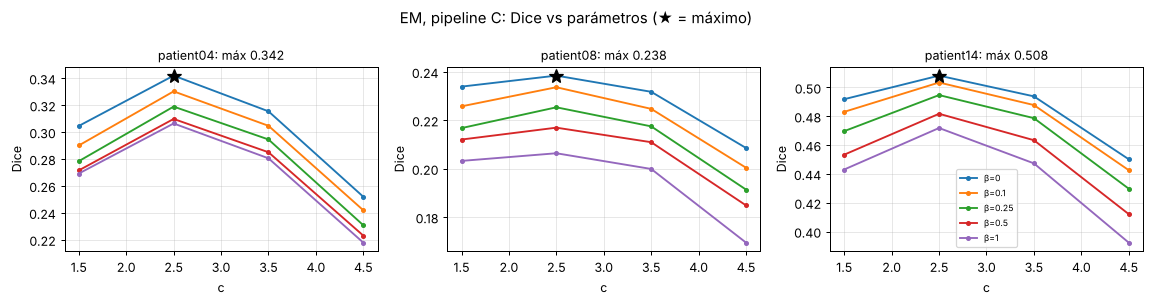

Tiempo del experimento: 177 s


,c (pac. 1),β (pac. 1),Dice paso 2 (transferido),c propio,β propio,Dice paso 3 (propio),Pérdida (paso 3 - paso 2)
Paciente,,,,,,,
patient04,2.500,0.000,0.342,2.500,0.000,0.342,0.000
patient08,2.500,0.000,0.238,2.500,0.000,0.238,0.000
patient14,2.500,0.000,0.508,2.500,0.000,0.508,0.000


In [26]:
GRILLA[('EM', 'C')] = ([1.5, 2.5, 3.5, 4.5], [0, 0.1, 0.25, 0.5, 1], ('c', 'β'))
GRILLA[('GBM', 'C')] = ([3, 4, 5, 6, 8], [0, 0.25, 0.5, 1, 2], ('K', 'β'))

g1, g2, nom = GRILLA[('EM', 'C')]
PARAMETROS[('EM', 'C')], exp_em_C, barr_em_C = experimento_parametros(casos_em, em_C, g1, g2, nom, 'EM, pipeline C')
exp_em_C

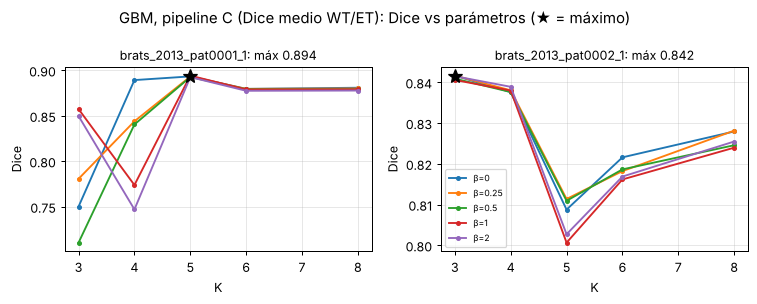

Tiempo del experimento: 387 s


,K (pac. 1),β (pac. 1),Dice paso 2 (transferido),K propio,β propio,Dice paso 3 (propio),Pérdida (paso 3 - paso 2)
Paciente,,,,,,,
brats_2013_pat0001_1,5.000,1.000,0.894,5.000,1.000,0.894,0.000
brats_2013_pat0002_1,5.000,1.000,0.801,3.000,0.000,0.842,0.041


In [27]:
g1, g2, nom = GRILLA[('GBM', 'C')]
PARAMETROS[('GBM', 'C')], exp_gbm_C, barr_gbm_C = experimento_parametros(casos_gbm, gbm_C, g1, g2, nom, 'GBM, pipeline C (Dice medio WT/ET)')
exp_gbm_C

### 5.6 Resultados del *pipeline* C (parámetros elegidos en el paciente 1)

In [28]:
seg_em_C, tab = aplicar_y_registrar('EM', 'C', em_C, casos_em); display(tab)
seg_gbm_C, tab = aplicar_y_registrar('GBM', 'C', gbm_C, casos_gbm); display(tab)

EM, pipeline C: parámetros (2.5, 0) elegidos en patient04


,Dice,Jaccard,Sens,VPP,EV,Detección,FP lesiones,Dice <50
Paciente,,,,,,,,
patient04,0.342,0.206,0.211,0.905,-0.767,0.191,26,0.019
patient08,0.238,0.135,0.181,0.349,-0.481,0.220,31,0.000
patient14,0.508,0.341,0.379,0.769,-0.507,0.167,35,0.009


GBM, pipeline C: parámetros (5, 1) elegidos en brats_2013_pat0001_1


,Dice WT,Jaccard WT,Sens WT,VPP WT,EV WT,Dice ET,Jaccard ET,Sens ET,VPP ET,EV ET
Paciente,,,,,,,,,,
brats_2013_pat0001_1,0.918,0.849,0.927,0.910,0.020,0.870,0.770,0.907,0.836,0.086
brats_2013_pat0002_1,0.891,0.803,0.836,0.953,-0.122,0.711,0.551,0.632,0.811,-0.221


## 6. Comparación

### 6.1 Tablas comparativas

Una tabla por problema, con una fila por *pipeline* y paciente. Indico en qué paciente se eligieron los parámetros y sus valores. En EM, todas las filas usan los parámetros elegidos en patient04 (paso 2 del experimento), así que la fila de patient04 está optimizada sobre su propia referencia y es optimista.

In [29]:
PIPES = {'A': (em_A, gbm_A), 'B': (em_B, gbm_B), 'C': (em_C, gbm_C)}

def tabla_comparativa(problema, casos):
    filas = []
    for p in PIPES:
        p1, p2 = PARAMETROS[(problema, p)]
        n1, n2 = GRILLA[(problema, p)][2]
        for c in casos:
            filas.append({'Pipeline': p, 'Paciente': c['nombre'], 'Parámetros elegidos en': casos[0]['nombre'],
                          'Parámetros': f'{n1}={p1:g}, {n2}={p2:g}',
                          **RESULTADOS_FINALES[(problema, p, c['nombre'])]})
    return pd.DataFrame(filas).set_index(['Pipeline', 'Paciente'])

tabla_em_final = tabla_comparativa('EM', casos_em)
tabla_em_final.to_csv(RESULTADOS / 'tabla_comparativa_EM.csv')
tabla_em_final

Parámetros elegidos en     Parámetros  Dice  Jaccard  Sens   VPP     EV  Detección  FP lesiones  Dice <50
Pipeline Paciente                                                                                                           
A        patient04              patient04     κ=0.5, c=2 0.525    0.356 0.425 0.687 -0.381      0.291          114     0.051
         patient08              patient04     κ=0.5, c=2 0.102    0.054 0.609 0.056  9.942      0.540          166     0.111
         patient14              patient04     κ=0.5, c=2 0.415    0.262 0.658 0.303  1.171      0.450          221     0.011
B        patient04              patient04  f_c=0.15, k=7 0.438    0.280 0.619 0.339  0.828      0.482           59     0.011
         patient08              patient04  f_c=0.15, k=7 0.057    0.029 0.480 0.030 14.887      0.340           22     0.001
         patient14              patient04  f_c=0.15, k=7 0.183    0.101 0.717 0.105  5.836      0.400           44     0.002
C        patient04              patient04     c=2.5, β=0 0.342    0.206 0.211 0.905 -0.767      0.191           26     0.019
         patient08              patient04     c=2.5, β=0 0.238    0.135 0.181 0.349 -0.481      0.220           31     0.000
         patient14              patient04     c=2.5, β=0 0.508    0.341 0.379 0.769 -0.507      0.167           35     0.009

**Resumen de EM para los pacientes 2 y 3** (patient08 y patient14): media ± desviación estándar del Dice, por separado para el paso 2 (parámetros transferidos desde patient04) y el paso 3 (parámetros propios de cada paciente). Con dos o tres pacientes no hay base para hablar de significancia estadística, así que la desviación estándar sólo describe la dispersión.

In [30]:
experimentos_em = {'A': exp_em_A, 'B': exp_em_B, 'C': exp_em_C}
filas = []
for p, ex in experimentos_em.items():
    sub = ex.iloc[1:]
    filas.append({'Pipeline': p,
                  'Dice paso 2 (transferido)': f"{sub['Dice paso 2 (transferido)'].mean():.3f} ± {sub['Dice paso 2 (transferido)'].std():.3f}",
                  'Dice paso 3 (propio)': f"{sub['Dice paso 3 (propio)'].mean():.3f} ± {sub['Dice paso 3 (propio)'].std():.3f}",
                  'Pérdida media (paso 3 - paso 2)': sub['Pérdida (paso 3 - paso 2)'].mean()})
resumen_em = pd.DataFrame(filas).set_index('Pipeline')
resumen_em.to_csv(RESULTADOS / 'resumen_EM_pacientes2y3.csv')
resumen_em

,Dice paso 2 (transferido),Dice paso 3 (propio),Pérdida media (paso 3 - paso 2)
Pipeline,,,
A,0.258 ± 0.221,0.449 ± 0.189,0.191
B,0.120 ± 0.089,0.143 ± 0.079,0.024
C,0.373 ± 0.191,0.373 ± 0.191,0.000


In [31]:
# Resumen de todas las métricas (media ± DE sobre los pacientes 2 y 3, parámetros transferidos)
cols = ['Dice', 'Jaccard', 'Sens', 'VPP', 'EV', 'Detección', 'FP lesiones', 'Dice <50']
t = tabla_em_final[tabla_em_final.index.get_level_values('Paciente') != casos_em[0]['nombre']][cols]
t.groupby(level='Pipeline').agg(lambda s: f'{s.mean():.3f} ± {s.std():.3f}')

,Dice,Jaccard,Sens,VPP,EV,Detección,FP lesiones,Dice <50
Pipeline,,,,,,,,
A,0.258 ± 0.221,0.158 ± 0.147,0.633 ± 0.034,0.179 ± 0.175,5.556 ± 6.202,0.495 ± 0.064,193.500 ± 38.891,0.061 ± 0.071
B,0.120 ± 0.089,0.065 ± 0.051,0.598 ± 0.168,0.068 ± 0.053,10.361 ± 6.400,0.370 ± 0.042,33.000 ± 15.556,0.001 ± 0.001
C,0.373 ± 0.191,0.238 ± 0.145,0.280 ± 0.140,0.559 ± 0.297,-0.494 ± 0.019,0.193 ± 0.038,33.000 ± 2.828,0.004 ± 0.006


In [32]:
tabla_gbm_final = tabla_comparativa('GBM', casos_gbm)
tabla_gbm_final.to_csv(RESULTADOS / 'tabla_comparativa_GBM.csv')
tabla_gbm_final

Parámetros elegidos en      Parámetros  Dice WT  Jaccard WT  Sens WT  VPP WT  EV WT  Dice ET  Jaccard ET  Sens ET  VPP ET  EV ET
Pipeline Paciente                                                                                                                                             
A        brats_2013_pat0001_1   brats_2013_pat0001_1  κ=2, n_iter=10    0.875       0.778    0.867   0.884 -0.018    0.748       0.597    0.668   0.849 -0.214
         brats_2013_pat0002_1   brats_2013_pat0001_1  κ=2, n_iter=10    0.910       0.835    0.921   0.899  0.024    0.777       0.636    0.814   0.744  0.094
B        brats_2013_pat0001_1   brats_2013_pat0001_1    f_c=0.2, k=6    0.885       0.793    0.820   0.961 -0.147    0.786       0.647    0.692   0.909 -0.239
         brats_2013_pat0002_1   brats_2013_pat0001_1    f_c=0.2, k=6    0.900       0.817    0.844   0.963 -0.123    0.801       0.668    0.680   0.974 -0.302
C        brats_2013_pat0001_1   brats_2013_pat0001_1        K=5, β=1    0.918       0.849    0.927   0.910  0.020    0.870       0.770    0.907   0.836  0.086
         brats_2013_pat0002_1   brats_2013_pat0001_1        K=5, β=1    0.891       0.803    0.836   0.953 -0.122    0.711       0.551    0.632   0.811 -0.221

### 6.2 Figuras: contornos sobre el mismo corte

En cada problema uso el mismo corte para la referencia y los tres *pipelines* (el de mayor área de referencia).

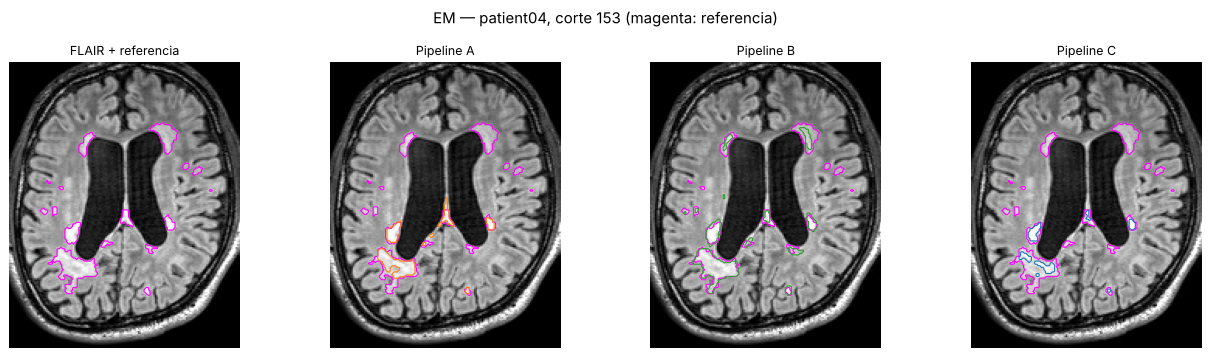

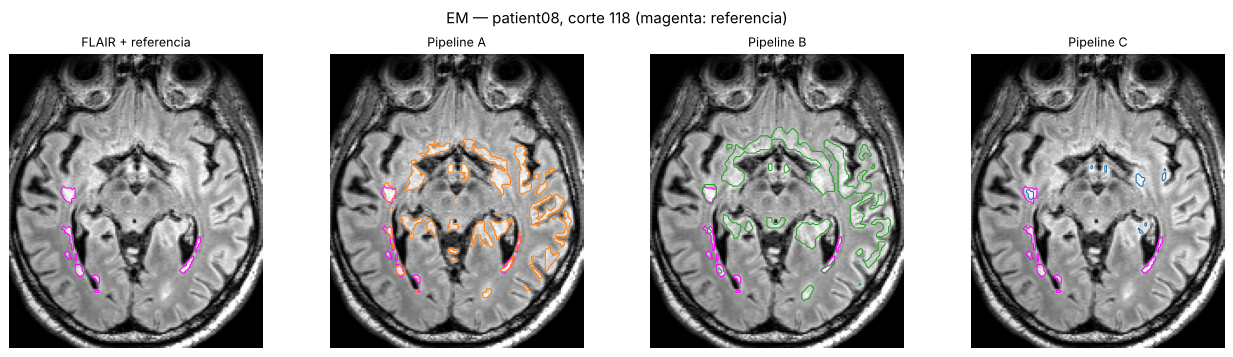

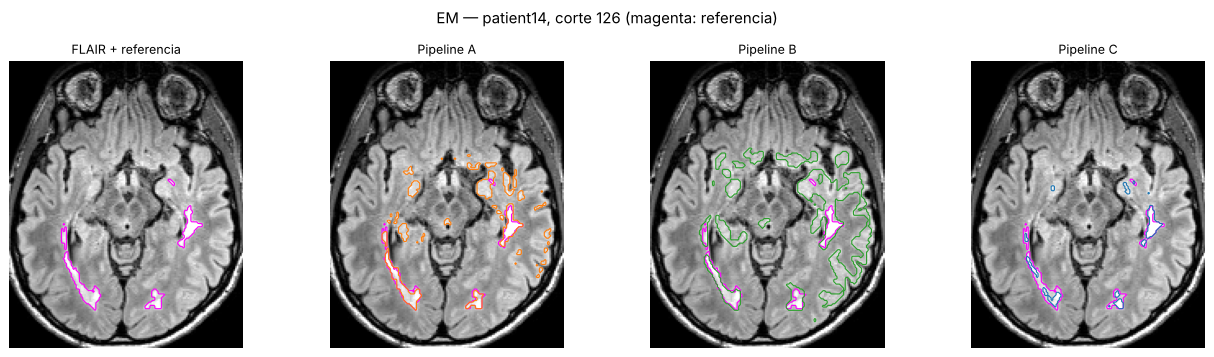

In [33]:
for c in casos_em:
    segs = {f'Pipeline {p}': s[c['nombre']] for p, s in zip('ABC', [seg_em_A, seg_em_B, seg_em_C])}
    figura_contornos(c, segs, 'EM')

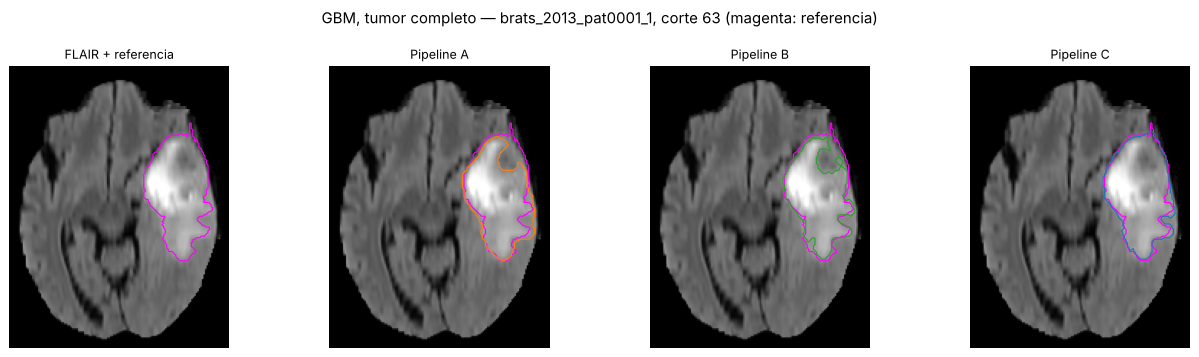

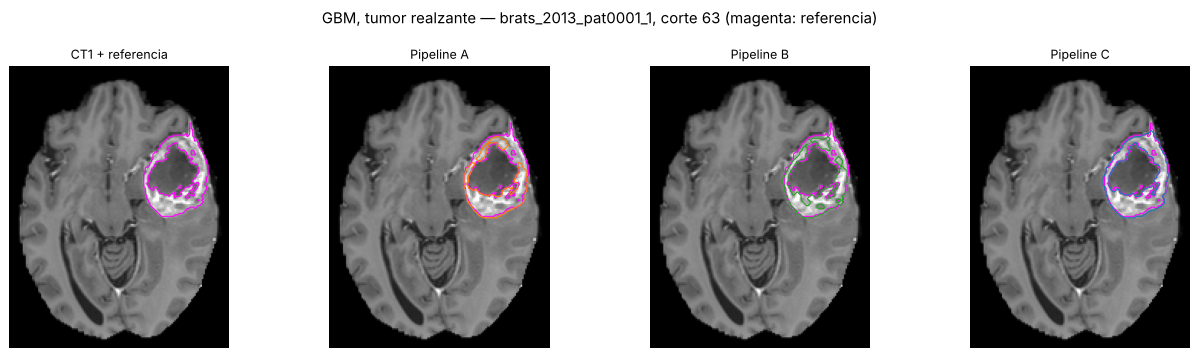

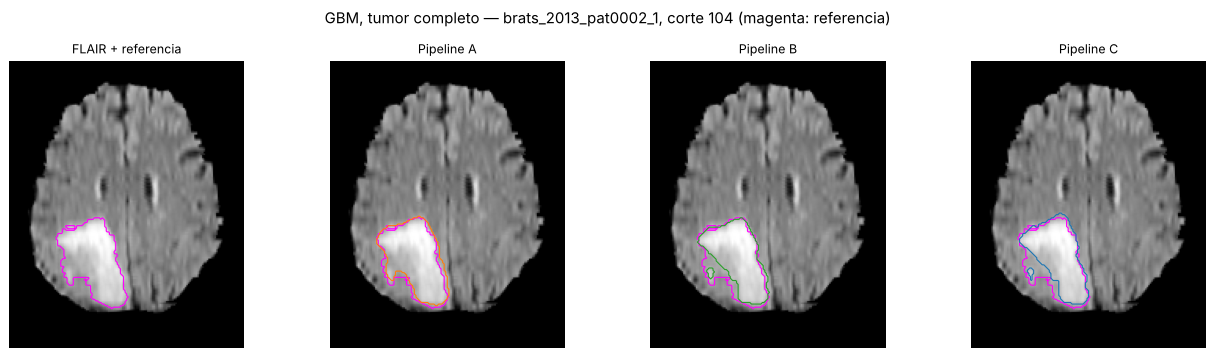

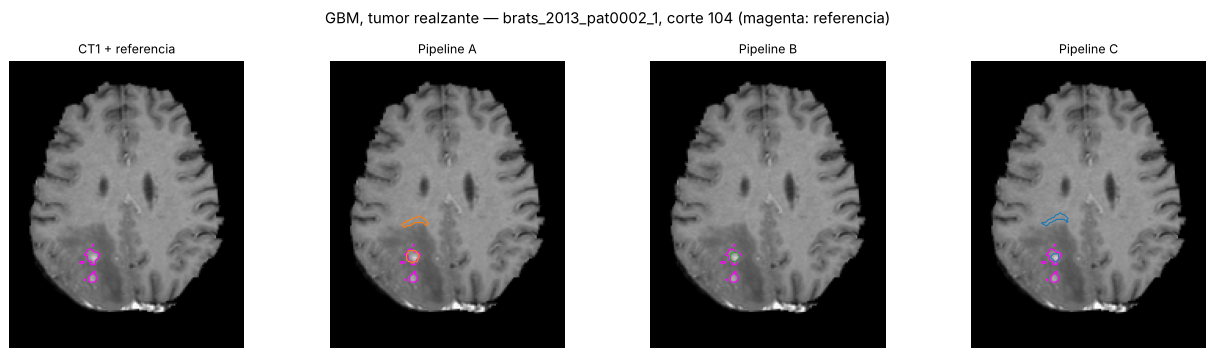

In [34]:
for c in casos_gbm:
    for nombre, idx, ref_key, fondo in [('tumor completo', 0, 'ref_wt', 'FLAIR'), ('tumor realzante', 1, 'ref_et', 'CT1')]:
        segs = {f'Pipeline {p}': s[c['nombre']][idx] for p, s in zip('ABC', [seg_gbm_A, seg_gbm_B, seg_gbm_C])}
        figura_contornos(c, segs, f'GBM, {nombre}', fondo=fondo, ref_key=ref_key, k=corte_max(c['ref_wt']))

### 6.3 Mapas de error

Verde: verdaderos positivos; **rojo: falsos positivos**; **azul: falsos negativos**.

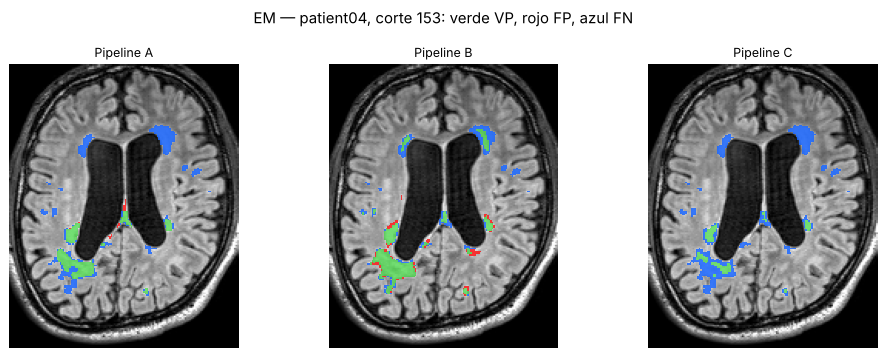

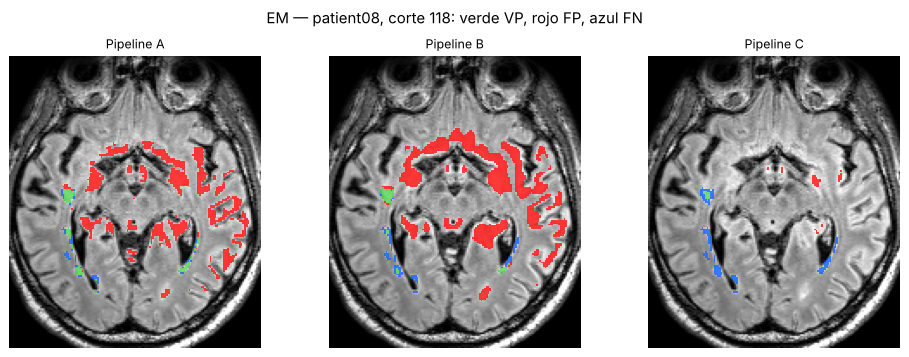

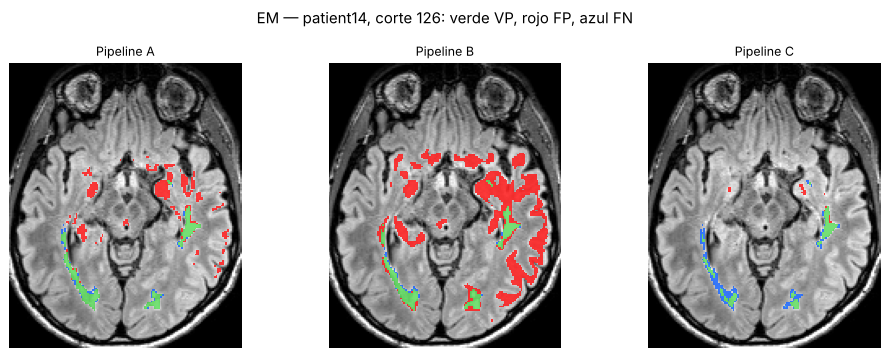

In [35]:
for c in casos_em:
    segs = {f'Pipeline {p}': s[c['nombre']] for p, s in zip('ABC', [seg_em_A, seg_em_B, seg_em_C])}
    mapa_errores(c, segs, 'EM')

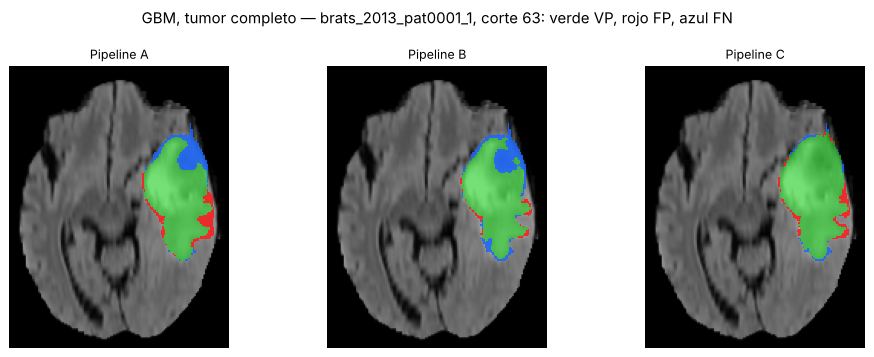

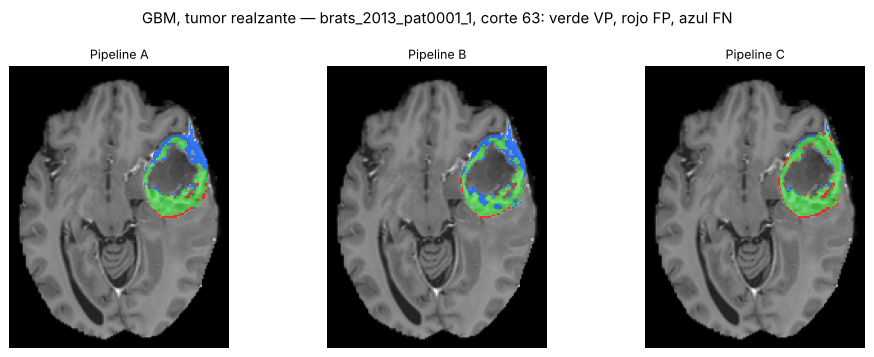

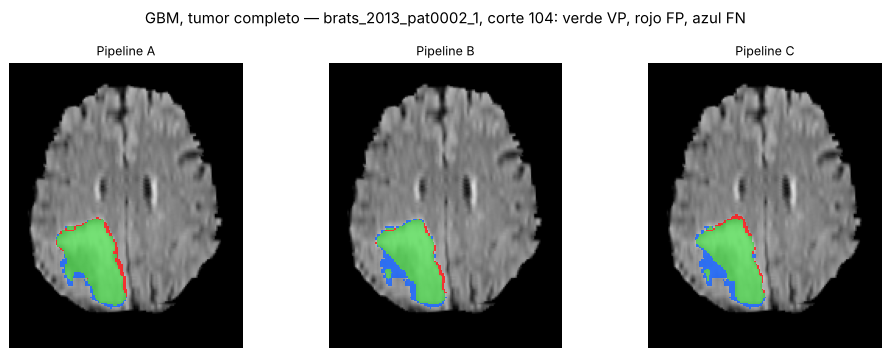

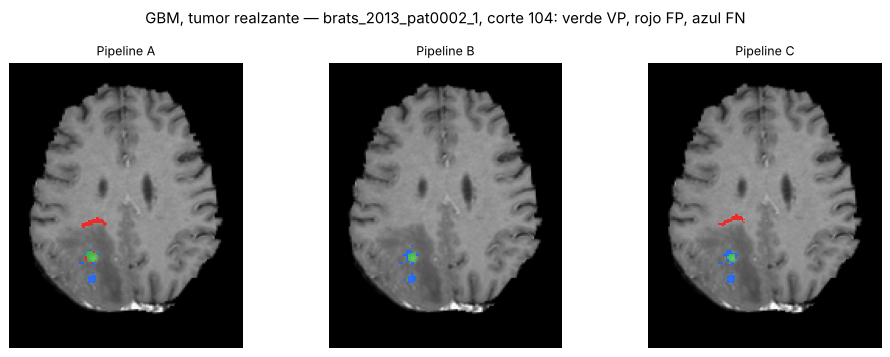

In [36]:
for c in casos_gbm:
    k = corte_max(c['ref_wt'])
    for nombre, idx, ref_key, fondo in [('tumor completo', 0, 'ref_wt', 'FLAIR'), ('tumor realzante', 1, 'ref_et', 'CT1')]:
        segs = {f'Pipeline {p}': s[c['nombre']][idx] for p, s in zip('ABC', [seg_gbm_A, seg_gbm_B, seg_gbm_C])}
        mapa_errores(c, segs, f'GBM, {nombre}', fondo=fondo, ref_key=ref_key, k=k)

### 6.4 Ablación

Para cada *pipeline*, con los mismos parámetros (los elegidos en el paciente 1), repito la evaluación:

* **sin filtrado** (sin Perona-Malik en A, sin Butterworth en B, sin el suavizado gaussiano en C),
* **sin postproceso**,
* y, en el *pipeline* C, con **β = 0** (máxima verosimilitud sin contexto).

La tabla muestra **ΔDice = Dice(variante) − Dice(completo)**. Un valor negativo significa que esa etapa aportaba ganancia, y uno positivo que la etapa empeoraba el resultado.

In [37]:
def ablacion(problema, casos):
    filas = []
    for p, fns in PIPES.items():
        fn = fns[0] if problema == 'EM' else fns[1]
        p1, p2 = PARAMETROS[(problema, p)]
        variantes = {'completo': dict(),
                     'sin filtrado': dict(filtrar=False),
                     'sin postproceso': dict(posproceso=False)}
        if p == 'C':
            variantes['β = 0 (sin MRF)'] = 'beta0'
        for c in casos:
            base = None
            for nombre, kw in variantes.items():
                if kw == 'beta0':
                    seg = fn(c, p1, 0)
                else:
                    seg = fn(c, p1, p2, **kw)
                met = evaluar(c, seg)
                if problema == 'EM':
                    d = {'Dice': met['Dice'], 'Detección': met['Detección'], 'FP lesiones': met['FP lesiones']}
                else:
                    d = {'Dice WT': met['Dice WT'], 'Dice ET': met['Dice ET']}
                if base is None:
                    base = d
                fila = {'Pipeline': p, 'Variante': nombre, 'Paciente': c['nombre']}
                for k_, v in d.items():
                    fila[k_] = v if nombre == 'completo' else v - base[k_]
                filas.append(fila)
    return pd.DataFrame(filas)

t0 = time.time()
abl_em = ablacion('EM', casos_em)
print(f'{time.time() - t0:.0f} s')
abl_em.to_csv(RESULTADOS / 'ablacion_EM.csv', index=False)
print('EM: fila "completo" = valor absoluto; resto = diferencia respecto del completo')
abl_em.pivot_table(index=['Pipeline', 'Variante'], columns='Paciente', values='Dice', sort=False)

34 s
EM: fila "completo" = valor absoluto; resto = diferencia respecto del completo


Paciente                  patient04  patient08  patient14
Pipeline Variante                                        
A        completo             0.525      0.102      0.415
         sin filtrado        -0.066      0.019     -0.034
         sin postproceso     -0.012     -0.012     -0.042
B        completo             0.438      0.057      0.183
         sin filtrado        -0.058      0.046      0.040
         sin postproceso     -0.007     -0.004     -0.008
C        completo             0.342      0.238      0.508
         sin filtrado        -0.096      0.027     -0.032
         sin postproceso     -0.002     -0.004     -0.009
         β = 0 (sin MRF)      0.000      0.000      0.000

In [38]:
# Promedio sobre los tres pacientes de EM (Dice, detección y FP lesionales)
abl_em.groupby(['Pipeline', 'Variante'], sort=False)[['Dice', 'Detección', 'FP lesiones']].mean()

Dice  Detección  FP lesiones
Pipeline Variante                                      
A        completo         0.347      0.427      167.000
         sin filtrado    -0.027      0.100      257.333
         sin postproceso -0.022      0.039      337.333
B        completo         0.226      0.407       41.667
         sin filtrado     0.009      0.251      480.333
         sin postproceso -0.007      0.017       13.000
C        completo         0.363      0.193       30.667
         sin filtrado    -0.034      0.073       89.333
         sin postproceso -0.005      0.020       34.000
         β = 0 (sin MRF)  0.000      0.000        0.000

In [39]:
abl_gbm = ablacion('GBM', casos_gbm)
abl_gbm.to_csv(RESULTADOS / 'ablacion_GBM.csv', index=False)
print('GBM: fila "completo" = valor absoluto; resto = diferencia respecto del completo')
abl_gbm.pivot_table(index=['Pipeline', 'Variante'], columns='Paciente', values=['Dice WT', 'Dice ET'], sort=False)

GBM: fila "completo" = valor absoluto; resto = diferencia respecto del completo


Dice WT                                   Dice ET                     
Paciente                 brats_2013_pat0001_1 brats_2013_pat0002_1 brats_2013_pat0001_1 brats_2013_pat0002_1
Pipeline Variante                                                                                           
A        completo                       0.875                0.910                0.748                0.777
         sin filtrado                  -0.005                0.006               -0.055                0.036
         sin postproceso               -0.013               -0.066                0.016               -0.553
B        completo                       0.885                0.900                0.786                0.801
         sin filtrado                  -0.020               -0.024               -0.061               -0.101
         sin postproceso               -0.006               -0.063                0.025               -0.410
C        completo                       0.918                0.891                0.870                0.711
         sin filtrado                  -0.035                0.005               -0.017                0.036
         sin postproceso               -0.067               -0.192               -0.838               -0.711
         β = 0 (sin MRF)               -0.003               -0.003                0.001                0.019

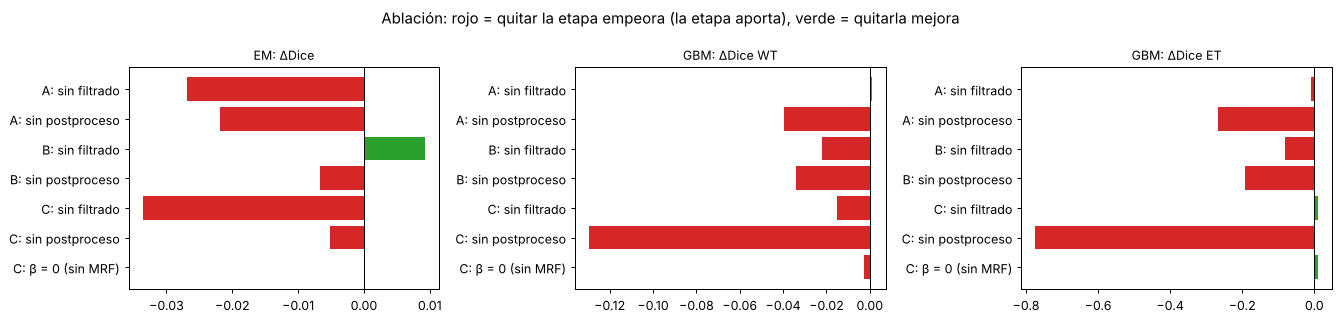

In [40]:
# Gráfico resumen de la ablación (ΔDice promedio sobre pacientes)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (titulo, df, col) in zip(axs, [('EM: ΔDice', abl_em, 'Dice'), ('GBM: ΔDice WT', abl_gbm, 'Dice WT'),
                                       ('GBM: ΔDice ET', abl_gbm, 'Dice ET')]):
    d = df[df.Variante != 'completo'].groupby(['Pipeline', 'Variante'], sort=False)[col].mean()
    etiquetas = [f'{a}: {b}' for a, b in d.index]
    ax.barh(etiquetas, d.values, color=['#d62728' if v < 0 else '#2ca02c' for v in d.values])
    ax.axvline(0, color='k', lw=0.8); ax.set_title(titulo); ax.invert_yaxis()
fig.suptitle('Ablación: rojo = quitar la etapa empeora (la etapa aporta), verde = quitarla mejora')
plt.tight_layout(); plt.show()

In [41]:
# Resumen automático de las cifras clave que se usan en la discusión
def fmt(x): return f'{x:.3f}'
for p in 'ABC':
    sub = experimentos_em[p].iloc[1:]
    print(f"EM {p}: params {tuple(float(v) for v in PARAMETROS[('EM', p)])}, Dice pac.1 {fmt(experimentos_em[p].iloc[0]['Dice paso 2 (transferido)'])}, "
          f"pac.2-3 transferido {fmt(sub['Dice paso 2 (transferido)'].mean())}, propio {fmt(sub['Dice paso 3 (propio)'].mean())}")
for p in 'ABC':
    r = tabla_gbm_final.loc[p]
    print(f"GBM {p}: params {tuple(float(v) for v in PARAMETROS[('GBM', p)])}, Dice WT {[fmt(v) for v in r['Dice WT']]}, Dice ET {[fmt(v) for v in r['Dice ET']]}")

EM A: params (0.5, 2.0), Dice pac.1 0.525, pac.2-3 transferido 0.258, propio 0.449
EM B: params (0.15, 7.0), Dice pac.1 0.438, pac.2-3 transferido 0.120, propio 0.143
EM C: params (2.5, 0.0), Dice pac.1 0.342, pac.2-3 transferido 0.373, propio 0.373
GBM A: params (2.0, 10.0), Dice WT ['0.875', '0.910'], Dice ET ['0.748', '0.777']
GBM B: params (0.2, 6.0), Dice WT ['0.885', '0.900'], Dice ET ['0.786', '0.801']
GBM C: params (5.0, 1.0), Dice WT ['0.918', '0.891'], Dice ET ['0.870', '0.711']


## 7. Discusión y recomendación

Las cifras de esta sección son las que aparecen en las tablas de la sección 6 (la última celda de código de 6.4 las resume). Todos los métodos son deterministas (semilla fija), así que al volver a ejecutar el cuaderno se obtienen los mismos valores.

### 7.1 Esclerosis múltiple

**Qué funcionó y qué no.** Ningún *pipeline* llega a un Dice cercano a la variabilidad entre evaluadores humanos (≈ 0,6–0,8, que es lo que reportan en la literatura los métodos con aprendizaje profundo en bases similares). Con parámetros transferidos desde patient04, el Dice medio en patient08 y patient14 fue **A 0,26 ± 0,22**, **B 0,12 ± 0,09** y **C 0,37 ± 0,19**. Los mapas de error explican por qué: en este FLAIR la **corteza es casi tan brillante como las lesiones**, y un clasificador que sólo mira la intensidad no puede separarlas. Los falsos positivos (rojo) se concentran en la corteza y alrededor de los ventrículos. El criterio de posición (margen de 3 mm) elimina sólo una parte.

**Métricas por lesión.** El Dice esconde diferencias importantes entre los *pipelines*:

* **A** es el más sensible (detecta ≈ 50 % de las lesiones de la referencia), pero a costa de ≈ 190 componentes falsas por paciente y de sobreestimar el volumen (EV ≫ 0 en patient08).
* **C** es el más conservador: tiene el VPP más alto (≈ 0,56), sólo ≈ 33 falsos positivos lesionales y siempre subestima el volumen (EV ≈ −0,5). En cambio, sólo detecta ≈ 20 % de las lesiones.
* **B** queda entre los dos en detección, pero tiene el peor Dice: con $k$ fijo, el grupo más brillante de *k-means* mezcla lesión y sustancia gris.
* El **Dice de lesiones < 50 vóxeles es casi nulo en los tres** (≤ 0,11). Las lesiones pequeñas, que son más de la mitad de las lesiones de cada paciente, prácticamente no se segmentan bien con métodos de intensidad. Un 0,5 de Dice global en patient04 viene casi entero de las lesiones periventriculares grandes.

**Experimento de parámetros (¿sirven los valores de un paciente para otro?).**

* **A** pierde en promedio **0,19 de Dice** al usar los valores de patient04. La causa es el umbral adaptativo $c$: patient04 tiene mucha carga lesional (40 mL) y su óptimo es $c=2$, mientras que patient08 (6 mL) necesita $c=3$. Con $c=2$, en patient08 el volumen segmentado es ≈ 10 veces el real, porque el umbral cae en la cola de la sustancia gris. Mi normalización robusta ancla la escala al parénquima, pero no a la carga lesional, y el umbral óptimo cambia con ella.
* **B** casi no pierde (0,02), pero sólo porque es malo en todos los pacientes.
* **C** **no pierde nada**: los mismos valores ($c=2{,}5$, $\beta=0$) son óptimos en los tres pacientes. Definir la clase lesión **relativa a la gaussiana de la sustancia gris de cada paciente** (en vez de un umbral sobre la intensidad) hace que el parámetro sea transferible.

**Ablación.**

* *Filtrado*: en patient04 los tres filtros ayudan (quitar el filtro baja el Dice 0,06–0,10), pero en patient08 quitarlo **sube** el Dice 0,02–0,05. El parámetro del filtro se eligió en patient04, así que su beneficio no se generaliza bien. Lo que sí es consistente es que el filtrado **reduce mucho los falsos positivos lesionales** (sin Butterworth, B pasa de ≈ 42 a ≈ 520 componentes falsas; sin Perona-Malik, A suma ≈ 260 más), porque el ruido produce muchos vóxeles sueltos sobre el umbral.
* *Postproceso*: el Dice cambia poco (0,002–0,04), porque los vóxeles que elimina son pocos, pero en A evita ≈ 340 componentes falsas por paciente. Es decir, su ganancia se ve en las métricas por lesión, no en el Dice.
* *MRF*: en EM el experimento eligió $\beta=0$ en los tres pacientes y la ablación da Δ = 0. **El contexto de Potts no ayuda en EM**, y el barrido muestra que el Dice baja de forma monótona al subir $\beta$. Es lo que predice la teoría (sección 5.3): el prior de Potts premia regiones grandes y compactas, y las lesiones de EM son lo contrario, pequeñas y aisladas. El MRF "limpia" justamente las lesiones pequeñas que se querían detectar.

**Recomendación para EM: *pipeline* C**, con la clase lesión definida como *outlier* de la mezcla gaussiana. Las razones:

1. Tiene el mejor Dice en los pacientes en los que no se ajustó (0,37 frente a 0,26 y 0,12).
2. Es el único cuyos parámetros se transfieren sin pérdida, lo que en la práctica es lo más importante, porque en un paciente nuevo no hay referencia para ajustar.
3. Tiene la mayor precisión (VPP) y la menor cantidad de falsos positivos lesionales.

La recomendación tiene matices. Su sensibilidad es baja (detecta ≈ 1 de cada 5 lesiones, casi ninguna pequeña), así que no sirve para **contar** lesiones; si el objetivo clínico fuera detectar lesiones nuevas, A detecta más, pero tendría que ajustarse paciente a paciente y revisarse a mano por sus falsos positivos. Además, conviene usarlo **sin MRF** ($\beta=0$) o con un prior que no penalice estructuras pequeñas. Para mejorar de verdad haría falta información que no es de intensidad: un mapa de probabilidad de sustancia blanca (atlas) para restringir la búsqueda, usar T1/T2 para separar la corteza, o directamente un modelo entrenado (p. ej. nnU-Net), que es el estado del arte en este problema.

### 7.2 Glioblastoma

**Qué funcionó.** Los tres *pipelines* segmentan bien el **tumor completo**, con Dice medio **A 0,89**, **B 0,89** y **C 0,90**: la hiperintensidad de edema y tumor en FLAIR es grande, contrasta mucho y forma un solo objeto. El **tumor realzante** es más difícil y diferencia más a los *pipelines*: Dice medio **A 0,76**, **B 0,79** y **C 0,79**, pero C pasa de 0,87 en el paciente donde se ajustó a 0,71 en el otro, mientras que **B se mantiene en 0,79–0,80 en ambos**. En los mapas de error, los errores del realce están en el borde interno del anillo (vóxeles de volumen parcial con la necrosis) y en vasos y plexos que realzan dentro del tumor completo.

**Experimento de parámetros.** Como pide el enunciado, elegí los parámetros sólo en el primer paciente. Al aplicarlos al segundo, la pérdida respecto de su propio óptimo es pequeña en todos los casos (**B 0,016**, A 0,029, C 0,041 de Dice medio WT/ET). B es el más estable.

**Ablación.**

* *Postproceso*: es **la etapa que más aporta** en GBM. Sin él, en el segundo paciente el realce cae entre 0,4 y 0,7 de Dice en los tres *pipelines* (y en C también en el primero, −0,84), y el tumor completo cae 0,06–0,19: el agrupamiento y los umbrales marcan como "tumor" o "realce" vasos, grasa, senos y plexos coroideos de todo el encéfalo. Quedarse con la componente conexa más grande y buscar el realce sólo dentro de ella es lo que convierte una clasificación de intensidades en una segmentación del tumor.
* *Filtrado*: el filtro de Fourier en B ayuda de forma consistente (sin él, el Dice baja 0,02 en el tumor completo y 0,06–0,10 en el realce). En cambio, Perona-Malik en A y el gaussiano en C dan resultados mixtos (±0,05). Una explicación es que el filtro de Butterworth reduce la varianza dentro de cada clase, y eso le sirve directamente a *k-means*, que supone grupos compactos.
* *MRF*: en GBM el experimento eligió $\beta=1$, pero quitar el MRF cambia el Dice en menos de 0,02 (incluso mejora el realce del segundo paciente). Aquí el contexto podría ayudar, porque las regiones son grandes, pero la morfología del postproceso (apertura y componente más grande) ya hace la misma "limpieza", y el MRF no agrega nada.

**Recomendación para GBM: *pipeline* B** (Butterworth en Fourier + *k-means* en dos etapas). Las razones:

1. Tiene el mejor Dice medio de realce (0,79) y es el más **estable** entre pacientes (0,786 y 0,801), con la menor pérdida al transferir parámetros.
2. Su etapa de filtrado sí aporta ganancia medible en la ablación.
3. Es el más simple y rápido de los tres.

C logra un tumor completo ligeramente mejor (0,90 frente a 0,89) y el mejor realce en el paciente donde se ajustó, pero es menos estable y su MRF no aporta, así que no justifica su costo. Si sólo interesara el tumor completo (por ejemplo, para planificar radioterapia sobre el edema), cualquiera de los tres sirve.

### 7.3 Limitaciones de este trabajo

* **Pocos pacientes.** Con tres pacientes de EM y dos de GBM no hay base para hablar de significancia estadística. Las desviaciones estándar sólo describen la dispersión, y las recomendaciones son tendencias, no conclusiones.
* **Datos de GBM sustitutos.** No pude bajar LUMIERE en el entorno donde ejecuté el cuaderno, así que evalué con dos glioblastomas de BraTS 2015 que sólo tienen FLAIR y CT1, con referencia **manual**. En LUMIERE habría T1 y T2 (útiles para el edema y la necrosis) y la referencia sería **automática** (DeepBraTumIA). Es posible que los Dice cambien, y parte del "error" contra una referencia automática puede ser error de la referencia. El código está preparado para usar los zip del curso sin cambios.
* **Selección de parámetros optimista.** En el paciente 1 los parámetros se eligen y se evalúan sobre la misma referencia, así que su Dice es optimista. Las cifras honestas son las de los pacientes 2 y 3 con parámetros transferidos (paso 2).
* **Métodos sólo de intensidad.** Ninguno de los tres usa forma ni anatomía (atlas), que es lo que les falta para separar las lesiones de EM de la corteza.

## 8. Referencias

* Lesjak Ž, Galimzianova A, Koren A, et al. *A novel public MR image dataset of multiple sclerosis patients with lesion segmentations based on multi-rater consensus.* Neuroinformatics 16:51–63 (2018). Datos: [Open MS data](https://github.com/muschellij2/open_ms_data).
* Suter Y, Knecht U, Valenzuela W, et al. *The LUMIERE dataset: Longitudinal Glioblastoma MRI with expert RANO evaluation.* Scientific Data 9:768 (2022). [doi:10.1038/s41597-022-01881-7](https://doi.org/10.1038/s41597-022-01881-7).
* Menze BH, et al. *The Multimodal Brain Tumor Image Segmentation Benchmark (BRATS).* IEEE TMI 34(10):1993–2024 (2015). Casos sustitutos tomados de los ejemplos de [DeepMedic](https://github.com/deepmedic/deepmedic) (Kamnitsas et al., 2017).
* Perona P, Malik J. *Scale-space and edge detection using anisotropic diffusion.* IEEE TPAMI 12(7):629–639 (1990).
* Otsu N. *A threshold selection method from gray-level histograms.* IEEE TSMC 9(1):62–66 (1979).
* Gonzalez RC, Woods RE. *Digital Image Processing*, 4.ª ed., cap. 4 (filtrado en frecuencia). Pearson (2018).
* Dempster AP, Laird NM, Rubin DB. *Maximum likelihood from incomplete data via the EM algorithm.* JRSS-B 39(1):1–38 (1977).
* Besag J. *On the statistical analysis of dirty pictures.* JRSS-B 48(3):259–302 (1986).
* Zhang Y, Brady M, Smith S. *Segmentation of brain MR images through a hidden Markov random field model and the expectation-maximization algorithm.* IEEE TMI 20(1):45–57 (2001).
* García-Lorenzo D, et al. *Review of automatic segmentation methods of multiple sclerosis white matter lesions on conventional MRI.* Medical Image Analysis 17(1):1–18 (2013).